[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_EquivariantAdversarialTransfer_Krumtunger2026.ipynb)

# Rotationally equivariant QNN and adversarial transfer: Krumtunger et al. 2026 step by step

**Paper.** M. Krumtunger, M. Sevior, M. Usman, *Feature-level analysis and adversarial transfer in rotationally equivariant quantum machine learning*, arXiv:2604.15552 (quant-ph), April 2026. DOI: [10.48550/arXiv.2604.15552](https://doi.org/10.48550/arXiv.2604.15552). Topic folder: *23 Adversarial attacks against QML* (also listed under 29, adversarial robustness defences).

**What this notebook does.** It rebuilds the paper's experimental pipeline on a CPU:

1. a rotationally equivariant quantum neural network (the model of West et al. 2024: amplitude encoding of an image sampled on concentric polygon rings, a quantum Fourier transform on the "orbital" qubits, a trainable circuit that only uses gates that commute with rotations, and a readout on the "radial" qubits);
2. the three diagnostic input transformations T1 (orthogonal circulant scrambling), T2 (ring-wise permutation) and T3 (ring-mean removal) that reveal which rotation-invariant image statistics the model uses (the paper's Table I);
3. **transfer attacks**: FGSM/PGD examples crafted on classical PyTorch surrogates (linear classifier, MLP, CNN, ResNet18) and fed to the quantum model that the attacker never queries (Figures 4 and 5);
4. two defences: adversarial training with surrogate-generated examples, and the paper's architectural fix, **projecting out the m = 0 Fourier sector** (the ring-averaged intensities) at the readout;
5. a side-by-side comparison of every number we can check, with an honest verdict per claim.

**How to run.** Open in Google Colab, choose a **CPU** runtime, *Run all*. `FAST_MODE = True` (default in the configuration cell) finishes in a few minutes; `FAST_MODE = False` runs the larger budget described in the configuration cell. Datasets (MNIST, Fashion-MNIST, CIFAR-10) are downloaded from public Hugging Face mirrors inside the notebook and cached in `DATA_DIR`; none of them is gated, so no token is needed (if you ever point the loader at a gated dataset, put your own token in Colab *Secrets* as `HF_TOKEN`).

**What you get at the end.** The re-drawn Table I (train/test on T1-T3), the transfer-robustness curves of Figures 4 and 5, the ring-invariance score of the linear surrogate (Table III), PennyLane drawings of every circuit architecture, and a table "paper vs this notebook".

## The paper in one page

**Problem.** Group-equivariant quantum models build a symmetry into the circuit. Does that make them adversarially robust? The paper studies *transfer attacks*: the adversary trains a classical surrogate on the same data, crafts an $\ell_\infty$-bounded perturbation with FGSM or PGD, and hopes it fools the (unseen) quantum model.

**Model (West et al. 2024).** An image is sampled at $N_r = 2^{n_{rad}}$ concentric regular polygons ("rings") with $N_\phi = 2^{n_{orb}}$ vertices each, giving values $x_{r,\phi}$. The amplitude-encoded state is $|\psi(x)\rangle = \|x\|^{-1}\sum_{r,\phi} x_{r,\phi}|r,\phi\rangle$ on $n_{rad}$ radial and $n_{orb}$ orbital qubits. Rotating the image by $360^\circ/N_\phi$ is a cyclic shift of $\phi$ (the group $\mathbb Z_{N_\phi}$). A quantum Fourier transform on the orbital register diagonalises that shift, so any gate that is *diagonal* on the orbital register (here CZ) commutes with the symmetry, while the radial register can carry arbitrary single-qubit rotations. The class of $x$ is the radial qubit $j$ with the largest $\langle Z_j\rangle$.

**Theory.** With an equivariant circuit and an invariant readout, the output depends on the input only through its group twirl, i.e. through the circular correlations $C_{r,r'}(\Delta\phi)=\sum_\alpha x_{r,\alpha}x_{r',\alpha-\Delta\phi}$. The $m=0$ Fourier sector carries the **ring-averaged intensities**.

**Probes.** T1 multiplies every ring by the same random orthogonal circulant matrix (provably leaves $C_{r,r'}$ unchanged, so accuracy must not change); T2 permutes the angular samples of each ring (keeps ring means, destroys correlations); T3 subtracts each ring mean (keeps the correlation shape, removes the $m=0$ sector).

**Claims we can test.**
* Table I: T1 changes nothing; T2 and T3 hurt, differently on different datasets (MNIST/RotMNIST rely more on T3-type structure than on ring means; STM/RotFMNIST/CIFAR rely strongly on ring means).
* Figures 4-5: the equivariant model is **not** automatically robust to transfer attacks (even a linear surrogate transfers); training on T3 data is more robust than clean, training on T2 data is not; adversarial training helps against the surrogate it used; projecting out $m=0$ at the readout helps against all four surrogates and costs less clean accuracy than adversarial training.
* Table III: the learned linear surrogate is partly "ring-invariant" (score $S_{ring}$ between 0.13 and 0.46).

**Data and budget in the paper.** STM (10 classes), MNIST and RotMNIST (digits 0-8), RotFMNIST (10 classes), CIFAR (frog vs airplane); 7,500 training and 500 test examples each; 12-13 qubits, depth 100, 10 epochs, batch 16, learning rate 3e-3, five seeds; 500 adversarial test images, $\epsilon\in[0,0.3]$ in steps of 0.025, PGD with 10 steps.

### What follows the paper and what had to be chosen

The paper's circuits (12-13 qubits, depth 100, 5 seeds x 6 training variants x 5 datasets) are far beyond a free Colab CPU, and several details are not given in the paper. The table lists every deviation; each one is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Datasets | STM, MNIST, RotMNIST, RotFMNIST, CIFAR | MNIST, RotMNIST, RotFMNIST, CIFAR (frog vs airplane). **STM** (scanning-tunnelling-microscope images of dopant qubits, built from private lab data) has no public source and is skipped |
| Classes | 9 (MNIST), 10 (FMNIST), 2 (CIFAR) | 5 classes for the MNIST/FMNIST families (digits 0-4; T-shirt, trouser, pullover, dress, coat), 2 for CIFAR. The readout needs one radial qubit per class, so fewer classes allow fewer qubits |
| Encoding $(n_{rad}, n_{orb})$ | (9,3), (10,3), (8,3) = 11-13 qubits, 64x64 or 32x32 source resolution | (5,3) = **8 qubits**: 32 rings x 8 vertices = 256 samples from a 32x32 grayscale image (bilinear sampling on a polar grid, ring radius up to the image edge) |
| Circuit depth | 100 layers | `DEPTH` layers (6 fast, 24 full); each layer = $R_z R_y R_x$ on every radial qubit, then a chain of CZ gates on all neighbouring qubits |
| Train / test size | 7,500 / 500 | `N_TRAIN` per dataset (400 fast, 2,000 full) + a validation split; 500 test images (200 fast) |
| Epochs, batch, learning rate | 10, 16, 3e-3 | `EPOCHS`, 32, 1e-2 (fewer optimisation steps, so a larger step); Adam |
| Seeds | 5 | `SEEDS` (2 fast, 3 full) |
| "Best weights" | checkpoint with best accuracy (test split not excluded) | checkpoint with best **validation** accuracy (no test-set selection) |
| Loss / logits | not stated | cross-entropy on $\tau\langle Z_j\rangle$ with $\tau$ = `TEMP` |
| Initial parameters | not stated | $\mathcal N(0, 0.1^2)$, same initial values for every training variant of one seed (paired comparison) |
| Simulator | not stated | own batched PyTorch state-vector simulator (all models of one dataset are trained at once); **asserted equal to the PennyLane QNode** |
| Surrogate training | AdamW, batch 128, wd 1e-4, best-test checkpoint | same optimiser, lr 1e-3, `SUR_EPOCHS[kind]` epochs (30/30/8/5 full), best-validation checkpoint; ResNet18 = torchvision architecture, 1-channel first layer |
| PGD | T=10, $\alpha=\max(\epsilon/T,10^{-3})$ | same; start at the clean point; iterates clipped to the valid pixel range [0,1] |
| Adversarial training | 50% of samples replaced by FGSM(LC) with $\epsilon\sim U[0.05,0.2]$ | same |
| Epsilon grid | 0 to 0.3 in steps of 0.025 for all surrogates | same for LC and MLP; CNN and ResNet18 (expensive PGD on CPU) use every second value (steps of 0.05) and the first `N_ATTACK_IMG` (100 fast, 250 full) test images instead of 500 |
| FGSM figures (appendix G) | shown | FGSM is implemented (used for adversarial training) but not evaluated as a separate curve |
| Rotated datasets | rotations in steps of 45 degrees | each image rotated by a random multiple of 45 degrees (bilinear resampling) before polar sampling |

## 1. Setup: installs, configuration, imports

In [1]:
# Installs. Colab already ships numpy, pandas, scikit-learn, matplotlib, torch, torchvision, pyarrow.
# The guard keeps a local environment (that already has everything) untouched.
import sys, importlib.util
IN_COLAB = "google.colab" in sys.modules
_needed = ["pennylane", "torch", "torchvision", "pyarrow", "huggingface_hub", "sklearn", "PIL"]
if IN_COLAB or any(importlib.util.find_spec(m) is None for m in _needed):
    !pip -q install "pennylane==0.45.1" huggingface_hub pyarrow pillow
    # A runtime restart is normally NOT required for these packages; if an import below fails, restart once.

In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
SEED = 42
FAST_MODE = False            # True: a few minutes demo; False: the larger budget below
DATA_DIR = "qc072_data"     # downloaded parquet files and cached trained parameters
IBM_TOKEN = ""              # unused: this notebook is simulation only (kept for template uniformity)

# Encoding (CHOICE: 8 qubits instead of the paper's 11-13, see the table above)
N_RAD, N_ORB = 5, 3         # radial / orbital qubits -> R = 32 rings, P = 8 vertices (Z_8 = rotations by 45 degrees)
IMG = 32                    # source images are resized to 32 x 32 grayscale

if FAST_MODE:
    DATASETS   = ["MNIST", "CIFAR"]
    N_TRAIN, N_VAL, N_TEST = 400, 100, 200
    SEEDS      = 2
    DEPTH      = 6
    EPOCHS     = 4
    SUR_EPOCHS = {"LC": 10, "MLP": 10, "CNN": 3, "ResNet18": 2}
    N_ATTACK_IMG = 100          # CNN / ResNet18 attacks use the first N test images (CPU time)
    EPS_GRID   = [round(e, 3) for e in [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3]]
else:
    DATASETS   = ["MNIST", "RotMNIST", "RotFMNIST", "CIFAR"]
    N_TRAIN, N_VAL, N_TEST = 2000, 300, 500
    SEEDS      = 3
    DEPTH      = 24
    EPOCHS     = 8
    SUR_EPOCHS = {"LC": 30, "MLP": 30, "CNN": 8, "ResNet18": 5}
    N_ATTACK_IMG = 250
    EPS_GRID   = [round(0.025 * i, 3) for i in range(13)]      # 0 .. 0.3 as in the paper

BATCH = 32                  # CHOICE (paper: 16)
LR = 1e-2                   # CHOICE (paper: 3e-3, but ~5x fewer optimisation steps here)
TEMP = 8.0                  # CHOICE: logit temperature tau in cross-entropy(tau * <Z_j>)
INIT_STD = 0.1              # CHOICE: parameter initialisation N(0, INIT_STD^2)
PGD_STEPS = 10              # paper
SUR_LR = 1e-3               # CHOICE: surrogate learning rate (AdamW, batch 128, weight decay 1e-4 as in the paper)

IMG_EPS_STRIDE = 2           # CHOICE: CNN/ResNet18 attacks use every 2nd epsilon of the grid (CPU time)
R, P = 2 ** N_RAD, 2 ** N_ORB
N_QUBITS = N_RAD + N_ORB
VARIANTS = ["clean", "T1", "T2", "T3", "adv", "M0"]   # training variants of the quantum model
print(f"FAST_MODE={FAST_MODE}  qubits={N_QUBITS} (radial {N_RAD}, orbital {N_ORB})  depth={DEPTH}  seeds={SEEDS}")

FAST_MODE=False  qubits=8 (radial 5, orbital 3)  depth=24  seeds=3


In [3]:
import os, io, time, copy, json, math, warnings
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.checkpoint import checkpoint
import torchvision
import pennylane as qml
from PIL import Image
from huggingface_hub import hf_hub_download
from sklearn.decomposition import PCA
warnings.filterwarnings("ignore")

# Hugging Face token: only needed for gated datasets (the three datasets used here are public).
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

# seeds everywhere
np.random.seed(SEED); torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_default_dtype(torch.float32)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.25})
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| pennylane", qml.__version__,
      "| numpy", np.__version__, "| threads", torch.get_num_threads())

torch 2.14.1+cpu | torchvision 0.29.1+cpu | pennylane 0.45.1 | numpy 2.5.4 | threads 4


## 2. Data: download, polar sampling and the three transformations

**Loading.** Each dataset is read from the public Hugging Face parquet mirror (`ylecun/mnist`, `zalando-datasets/fashion_mnist`, `uoft-cs/cifar10`). We draw a class-balanced, stratified subset: `N_TRAIN` + `N_VAL` images from the official training split (disjoint) and `N_TEST` images from the official test split.

**Polar sampling (Eq. 3).** Ring $r$ has radius $(r+0.5)/N_r$ of the image half-width and its $N_\phi$ vertices sit at angles $2\pi\phi/N_\phi$. The image is bilinearly interpolated at these points, giving a vector $x_{r,\phi}$ of $N_r N_\phi = 256$ values stored in the *radial-orbital ordering* $\text{index}=r\cdot N_\phi+\phi$ (the radial qubits are the most significant bits). This vector is also the input of the linear and MLP surrogates.

**Transformations (Appendix C).** All three act on the ring vectors $x_r\in\mathbb R^{N_\phi}$ of one image:
T1 multiplies every ring by the same random real orthogonal circulant matrix $O(\lambda)=F^\dagger \mathrm{diag}(\lambda)F$ (random phases, conjugate symmetric, $\lambda_0=1$); T2 permutes each ring independently; T3 subtracts each ring mean.

In [4]:
HF_SPECS = {   # key: (repo, parquet path pattern, image column, label column)
    "MNIST":  ("ylecun/mnist", "mnist/{split}-00000-of-00001.parquet", "image", "label"),
    "FMNIST": ("zalando-datasets/fashion_mnist", "fashion_mnist/{split}-00000-of-00001.parquet", "image", "label"),
    "CIFAR10": ("uoft-cs/cifar10", "plain_text/{split}-00000-of-00001.parquet", "img", "label"),
}
# CHOICE: class subsets (readout needs one radial qubit per class; N_RAD = 5 -> at most 5 classes)
DS_CFG = {
    "MNIST":     dict(key="MNIST",   classes=[0, 1, 2, 3, 4], names=["0", "1", "2", "3", "4"], rot=False),
    "RotMNIST":  dict(key="MNIST",   classes=[0, 1, 2, 3, 4], names=["0", "1", "2", "3", "4"], rot=True),
    "RotFMNIST": dict(key="FMNIST",  classes=[0, 1, 2, 3, 4],
                      names=["T-shirt", "Trouser", "Pullover", "Dress", "Coat"], rot=True),
    "CIFAR":     dict(key="CIFAR10", classes=[0, 6], names=["airplane", "frog"], rot=False),
}
_parquet_cache = {}
def load_parquet(key, split):
    if (key, split) not in _parquet_cache:
        repo, pat, icol, lcol = HF_SPECS[key]
        path = hf_hub_download(repo, pat.format(split=split), repo_type="dataset",
                               token=HF_TOKEN or None, local_dir=DATA_DIR)
        _parquet_cache[(key, split)] = pd.read_parquet(path, columns=[icol, lcol])
    return _parquet_cache[(key, split)]

def decode_gray(cell):
    im = Image.open(io.BytesIO(cell["bytes"])).convert("L")      # ITU-R 601 luma for CIFAR, identity for MNIST
    a = torch.from_numpy(np.asarray(im, dtype=np.float32) / 255.0)[None, None]
    if a.shape[-1] != IMG:
        a = F.interpolate(a, size=(IMG, IMG), mode="bilinear", align_corners=False)
    return a[0, 0]

def stratified_pick(labels, classes, n_total, gen):
    """class-balanced indices (n_total // len(classes) per class), returned class by class."""
    per = n_total // len(classes); out = []
    for c in classes:
        idx = np.flatnonzero(labels == c)
        out.append(gen.permutation(idx)[:per])
    return out

def rotate_images(imgs, ks):
    """rotate each (H,W) image by ks[i] * 45 degrees about its centre (bilinear, zero padding)."""
    ang = torch.as_tensor(ks, dtype=torch.float32) * (math.pi / 4)
    c, s = torch.cos(ang), torch.sin(ang)
    theta = torch.zeros(len(ang), 2, 3); theta[:, 0, 0] = c; theta[:, 0, 1] = -s; theta[:, 1, 0] = s; theta[:, 1, 1] = c
    grid = F.affine_grid(theta, imgs[:, None].shape, align_corners=False)
    return F.grid_sample(imgs[:, None], grid, mode="bilinear", padding_mode="zeros", align_corners=False)[:, 0]

def polar_encode(imgs):
    """(N,H,W) images in [0,1] -> (N, R*P) ring samples x[r*P+phi] (Eq. 3 before normalisation)."""
    N = imgs.shape[0]
    radii = (torch.arange(R, dtype=torch.float32) + 0.5) / R
    ang = 2 * math.pi * torch.arange(P, dtype=torch.float32) / P
    gx = radii[:, None] * torch.cos(ang)[None]; gy = radii[:, None] * torch.sin(ang)[None]
    grid = torch.stack([gx, gy], -1)[None].expand(N, R, P, 2)
    out = F.grid_sample(imgs[:, None], grid, mode="bilinear", padding_mode="zeros", align_corners=True)
    return out[:, 0].reshape(N, R * P)

def build_dataset(name):
    cfg = DS_CFG[name]
    gen = np.random.default_rng(SEED + 17)
    tr = load_parquet(cfg["key"], "train"); te = load_parquet(cfg["key"], "test")
    icol, lcol = HF_SPECS[cfg["key"]][2], HF_SPECS[cfg["key"]][3]
    ytr_all, yte_all = tr[lcol].to_numpy(), te[lcol].to_numpy()
    k = len(cfg["classes"])
    pick_tr = stratified_pick(ytr_all, cfg["classes"], N_TRAIN + N_VAL, gen)
    pick_te = stratified_pick(yte_all, cfg["classes"], N_TEST, gen)
    n_val_c = N_VAL // k
    tr_idx = np.concatenate([p[n_val_c:] for p in pick_tr]); va_idx = np.concatenate([p[:n_val_c] for p in pick_tr])
    te_idx = np.concatenate(pick_te)
    cmap = {c: i for i, c in enumerate(cfg["classes"])}
    def make(df, idx, ylab):
        imgs = torch.stack([decode_gray(df[icol].iloc[i]) for i in idx])
        y = torch.as_tensor([cmap[int(ylab[i])] for i in idx])
        p = gen.permutation(len(idx)); return imgs[p], y[p]
    d = {"name": name, "classes": cfg["names"], "C": k}
    for tag, (df, idx, yl) in {"tr": (tr, tr_idx, ytr_all), "va": (tr, va_idx, ytr_all), "te": (te, te_idx, yte_all)}.items():
        imgs, y = make(df, idx, yl)
        if cfg["rot"]:                                   # discrete rotations (Z_8), as in RotMNIST / RotFMNIST
            ks = gen.integers(0, P, size=len(y)); imgs = rotate_images(imgs, ks).clamp(0, 1)
        d["img_" + tag], d["y_" + tag] = imgs, y
        d["X_" + tag] = polar_encode(imgs)
    return d

t0 = time.time()
DATA = {}
for name in DATASETS:
    DATA[name] = build_dataset(name)
    d = DATA[name]
    print(f"{name:10s} train {tuple(d['img_tr'].shape)} val {tuple(d['img_va'].shape)} test {tuple(d['img_te'].shape)} "
          f"-> encoded {tuple(d['X_tr'].shape)}   ({time.time()-t0:.0f}s)")

MNIST      train (2000, 32, 32) val (300, 32, 32) test (500, 32, 32) -> encoded (2000, 256)   (4s)


RotMNIST   train (2000, 32, 32) val (300, 32, 32) test (500, 32, 32) -> encoded (2000, 256)   (6s)


fashion_mnist/train-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 30.9MB            

fashion_mnist/train-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

fashion_mnist/test-00000-of-00001.parque(…): reconstructing file:   0%|          |  0.00B / 5.18MB            

fashion_mnist/test-00000-of-00001.parque(…): downloading bytes:           |  0.00B            

RotFMNIST  train (2000, 32, 32) val (300, 32, 32) test (500, 32, 32) -> encoded (2000, 256)   (12s)


CIFAR      train (2000, 32, 32) val (300, 32, 32) test (500, 32, 32) -> encoded (2000, 256)   (15s)


In [5]:
# ---- diagnostic transformations T1, T2, T3 (Appendix C), applied ring by ring to encoded vectors (N, R*P) ----
def t1_scramble(X, seed):
    """T1: same random orthogonal circulant O(lambda) on every ring of an image (new lambda per image)."""
    g = torch.Generator().manual_seed(seed)
    N = X.shape[0]; x = X.reshape(N, R, P).double()
    lam = torch.ones(N, P, dtype=torch.complex128)
    ph = torch.rand(N, P // 2 - 1, generator=g, dtype=torch.float64) * 2 * math.pi
    lam[:, 1:P // 2] = torch.polar(torch.ones_like(ph), ph)
    lam[:, P // 2] = torch.where(torch.rand(N, generator=g) < 0.5, -1.0, 1.0).to(torch.complex128)
    lam[:, P // 2 + 1:] = torch.conj(torch.flip(lam[:, 1:P // 2], dims=[1]))
    y = torch.fft.ifft(torch.fft.fft(x, dim=-1) * lam[:, None, :], dim=-1)
    assert y.imag.abs().max() < 1e-9, "O(lambda) must be real"
    return y.real.float().reshape(N, R * P)

def t2_permute(X, seed):
    """T2: independent random permutation of the angular samples of every ring."""
    g = torch.Generator().manual_seed(seed)
    N = X.shape[0]; x = X.reshape(N, R, P)
    perm = torch.rand(N, R, P, generator=g).argsort(-1)
    return torch.gather(x, -1, perm).reshape(N, R * P)

def t3_demean(X, seed=None):
    """T3: subtract every ring's mean."""
    N = X.shape[0]; x = X.reshape(N, R, P)
    return (x - x.mean(-1, keepdim=True)).reshape(N, R * P)

TRANSFORMS = {"T1": t1_scramble, "T2": t2_permute, "T3": t3_demean}
for name, d in DATA.items():
    for tag in ["tr", "te"]:
        for k, (tn, fn) in enumerate(TRANSFORMS.items()):
            d[f"X_{tn}_{tag}"] = fn(d["X_" + tag], SEED + 100 * k + (0 if tag == "tr" else 7))
print("transformed copies built for", list(DATA))

transformed copies built for ['MNIST', 'RotMNIST', 'RotFMNIST', 'CIFAR']


## Dataset Exploration and Visualisation

Everything below uses the real, labelled observations that the experiments use (no synthetic data). For each dataset we print the shape, the feature layout and the class counts, plot the class distribution, show example images with their polar sampling, and project the real encoded samples to 2-D with a PCA fitted on the **training split only**. The model uses *amplitude* encoding, not angle encoding, so there is no $[0,\pi]$ angle scaling to show; instead the second scatter uses the ring-averaged intensities (the $m=0$ Fourier sector), the very feature the paper finds brittle.

=== MNIST ===
  train      images (2000, 32, 32)  encoded (2000, 256)  class counts {'0': 400, '1': 400, '2': 400, '3': 400, '4': 400}
  validation images (300, 32, 32)  encoded (300, 256)  class counts {'0': 60, '1': 60, '2': 60, '3': 60, '4': 60}
  test       images (500, 32, 32)  encoded (500, 256)  class counts {'0': 100, '1': 100, '2': 100, '3': 100, '4': 100}
  features: 32 rings x 8 angles = 256 ring samples x[r,phi] (index r*8+phi); pixel range [0.00, 1.00]; original labels ['0', '1', '2', '3', '4']
=== RotMNIST ===
  train      images (2000, 32, 32)  encoded (2000, 256)  class counts {'0': 400, '1': 400, '2': 400, '3': 400, '4': 400}
  validation images (300, 32, 32)  encoded (300, 256)  class counts {'0': 60, '1': 60, '2': 60, '3': 60, '4': 60}
  test       images (500, 32, 32)  encoded (500, 256)  class counts {'0': 100, '1': 100, '2': 100, '3': 100, '4': 100}
  features: 32 rings x 8 angles = 256 ring samples x[r,phi] (index r*8+phi); pixel range [0.00, 1.00]; original labe

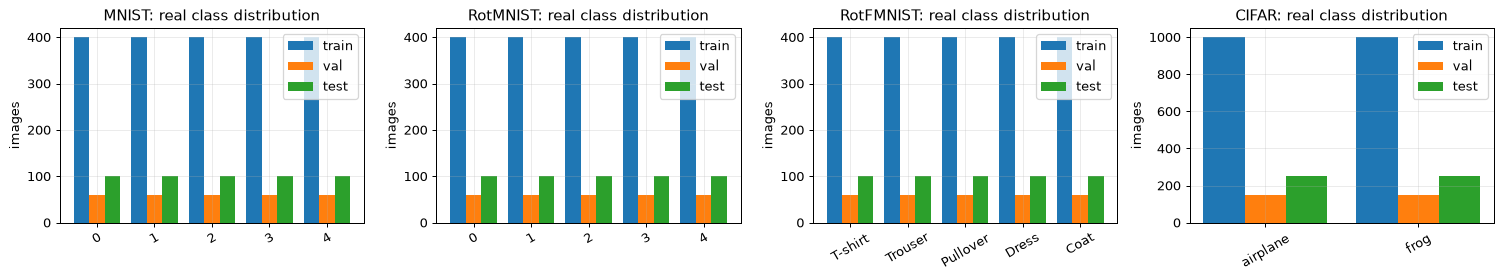

In [6]:
for name, d in DATA.items():
    print(f"=== {name} ===")
    for tag, full in [("tr", "train"), ("va", "validation"), ("te", "test")]:
        cnt = np.bincount(d["y_" + tag].numpy(), minlength=d["C"])
        print(f"  {full:10s} images {tuple(d['img_' + tag].shape)}  encoded {tuple(d['X_' + tag].shape)}  "
              f"class counts {dict(zip(d['classes'], cnt.tolist()))}")
    print(f"  features: {R} rings x {P} angles = {R*P} ring samples x[r,phi] (index r*{P}+phi); "
          f"pixel range [{d['img_tr'].min():.2f}, {d['img_tr'].max():.2f}]; original labels {d['classes']}")

fig, axs = plt.subplots(1, len(DATA), figsize=(4.2 * len(DATA), 3.2))
axs = np.atleast_1d(axs)
for ax, (name, d) in zip(axs, DATA.items()):
    w = 0.27
    for j, (tag, full) in enumerate([("tr", "train"), ("va", "val"), ("te", "test")]):
        cnt = np.bincount(d["y_" + tag].numpy(), minlength=d["C"])
        ax.bar(np.arange(d["C"]) + (j - 1) * w, cnt, w, label=full)
    ax.set_xticks(range(d["C"])); ax.set_xticklabels(d["classes"], rotation=30); ax.set_title(f"{name}: real class distribution")
    ax.set_ylabel("images"); ax.legend()
plt.tight_layout(); plt.show()

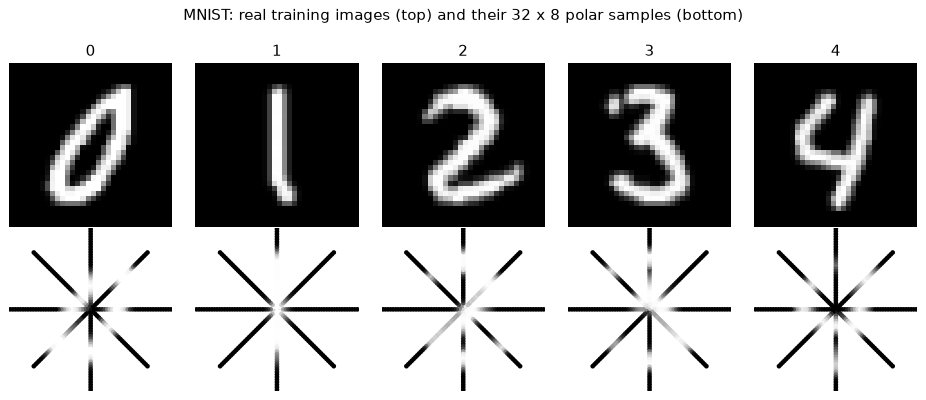

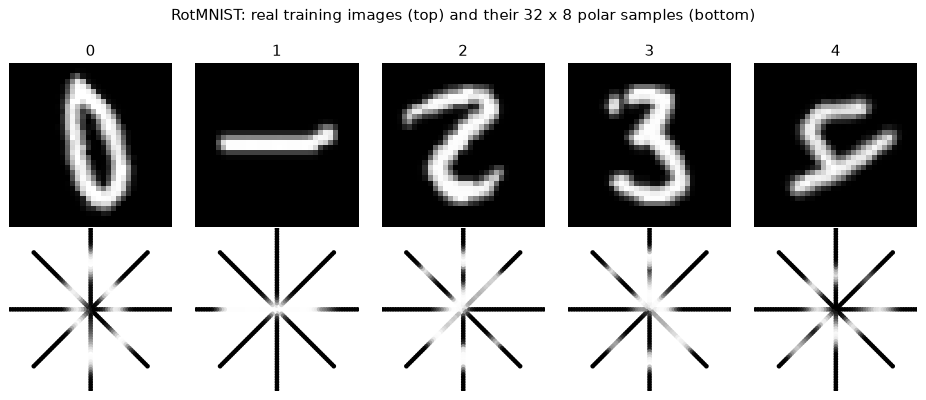

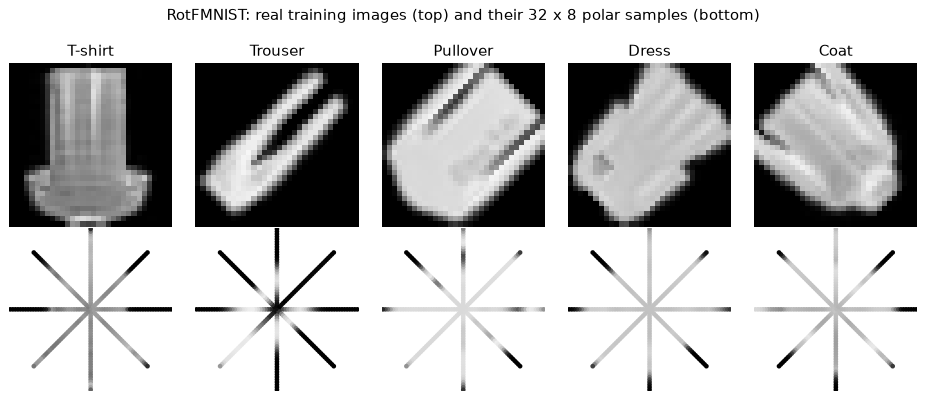

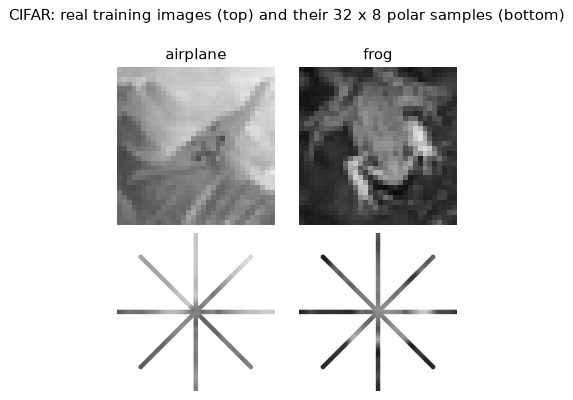

In [7]:
# example images (one per class) and their polar sampling, as in the paper's Fig. 1 / Fig. 3
def polar_xy():
    radii = (np.arange(R) + 0.5) / R; ang = 2 * np.pi * np.arange(P) / P
    return (radii[:, None] * np.cos(ang)[None]).ravel(), (radii[:, None] * np.sin(ang)[None]).ravel()
PX, PY = polar_xy()
for name, d in DATA.items():
    fig, axs = plt.subplots(2, d["C"], figsize=(2.1 * d["C"], 4.4))
    for c in range(d["C"]):
        i = int((d["y_tr"] == c).nonzero()[0, 0])
        axs[0, c].imshow(d["img_tr"][i], cmap="gray", vmin=0, vmax=1); axs[0, c].set_title(d["classes"][c]); axs[0, c].axis("off")
        axs[1, c].scatter(PX, -PY, c=d["X_tr"][i].numpy(), cmap="gray", vmin=0, vmax=1, s=14, edgecolors="none")
        axs[1, c].set_xlim(-1, 1); axs[1, c].set_ylim(-1, 1); axs[1, c].set_aspect("equal"); axs[1, c].axis("off")
        axs[1, c].set_facecolor("#7a7a7a")
    fig.suptitle(f"{name}: real training images (top) and their {R} x {P} polar samples (bottom)", y=1.0)
    plt.tight_layout(); plt.show()

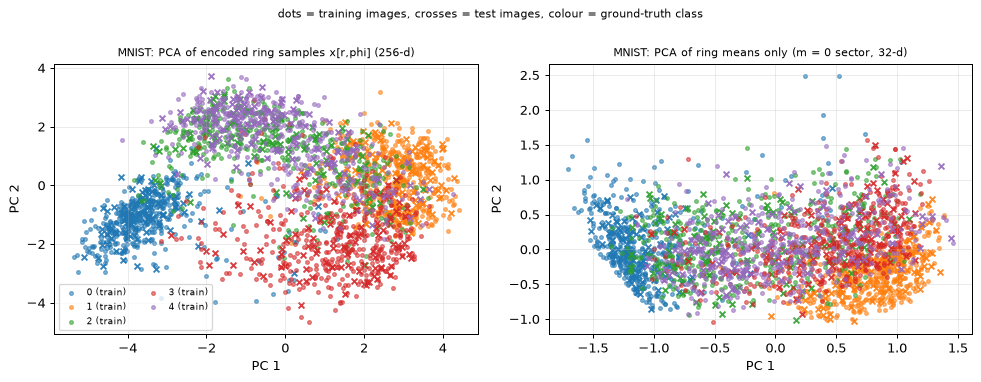

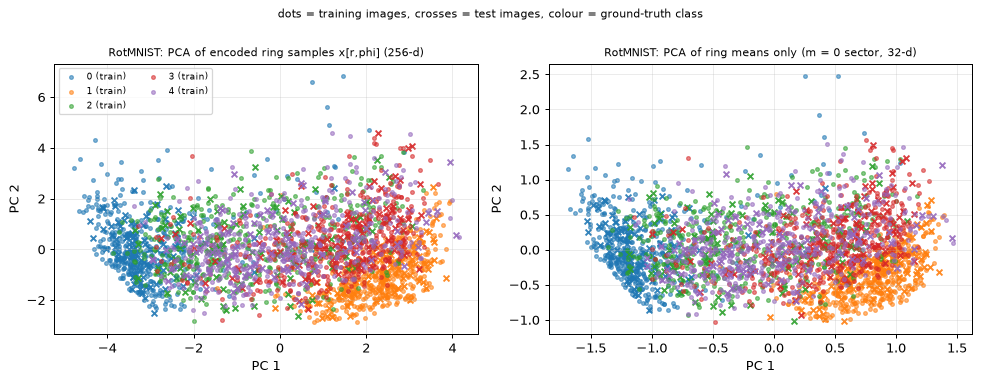

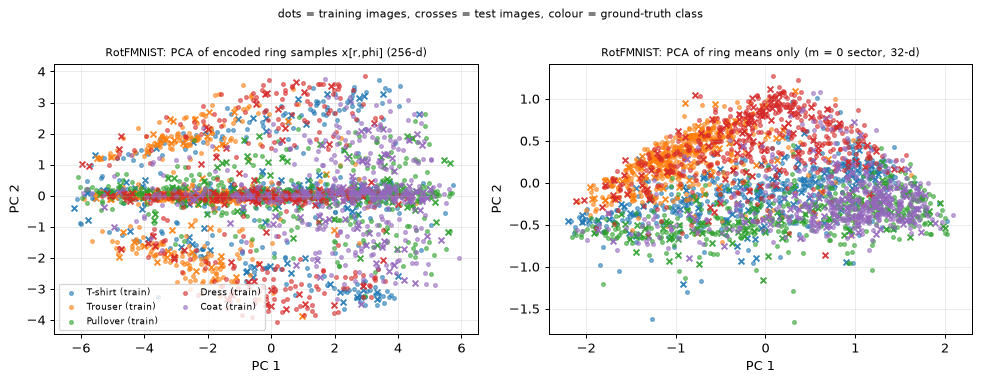

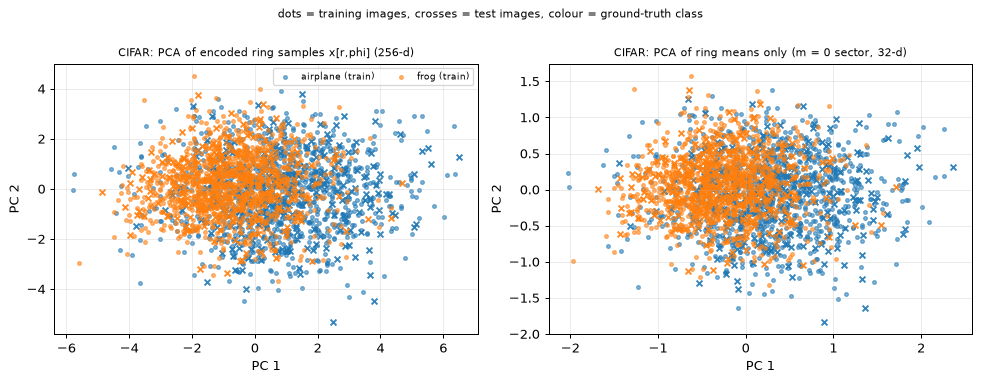

In [8]:
# 2-D scatter of real observations coloured by ground-truth label. PCA is fitted on the training split only.
palette = plt.cm.tab10.colors
for name, d in DATA.items():
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
    feats = {"encoded ring samples x[r,phi] (256-d)": (d["X_tr"], d["X_te"]),
             "ring means only (m = 0 sector, 32-d)": (d["X_tr"].reshape(-1, R, P).mean(-1), d["X_te"].reshape(-1, R, P).mean(-1))}
    for ax, (title, (A, B)) in zip(axs, feats.items()):
        pca = PCA(n_components=2, random_state=SEED).fit(A.numpy())
        Za, Zb = pca.transform(A.numpy()), pca.transform(B.numpy())
        for c in range(d["C"]):
            ax.scatter(*Za[d["y_tr"].numpy() == c].T, s=9, color=palette[c], alpha=0.55, label=f"{d['classes'][c]} (train)")
            ax.scatter(*Zb[d["y_te"].numpy() == c].T, s=22, color=palette[c], marker="x", alpha=0.9)
        ax.set_title(f"{name}: PCA of {title}", fontsize=9); ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2")
    axs[0].legend(fontsize=7, ncol=2)
    fig.suptitle("dots = training images, crosses = test images, colour = ground-truth class", y=1.0, fontsize=9)
    plt.tight_layout(); plt.show()

## 3. The rotationally equivariant quantum model (batched PyTorch simulator)

**Circuit** (qubits $0..n_{rad}-1$ radial, most significant bits first; qubits $n_{rad}..n-1$ orbital):

1. amplitude encoding $|\psi(x)\rangle=\|x\|^{-1}\sum_{r,\phi}x_{r,\phi}|r,\phi\rangle$;
2. $\mathrm{QFT}^\dagger$ on the orbital register, which diagonalises the cyclic shift $\phi\to\phi+1$ (orbital basis state $|m\rangle$ = Fourier mode $m$; $m=0$ is the ring mean);
3. `DEPTH` layers, each = $R_z(\theta_2)R_y(\theta_1)R_x(\theta_0)$ on every **radial** qubit followed by a CZ on every pair of neighbouring qubits in the chain $0-1-\dots-(n-1)$. CZ is diagonal, so on the orbital register it commutes with the symmetry; the radial register is untouched by the group. (`# CHOICE:` the paper draws "nearest-neighbour CZ" and does not say whether the chain also bridges radial and orbital qubits; we include the bridge so that the orbital sectors can influence the radial register.)
4. readout: $\langle Z_j\rangle$ on radial qubit $j$ for class $j$, prediction = argmax.

**Why a custom simulator.** The paper trains 5 seeds x 6 variants x 5 datasets. Here all models of one dataset (variants x seeds) are simulated in one batch: the radial layer is the Kronecker product of single-qubit gates, a $2^{n_{rad}}\times2^{n_{rad}}$ matrix acting on every orbital sector at once; the CZ chain is a $\pm1$ diagonal. The complex state is carried as stacked real and imaginary parts to use fast real matrix products. Gradients come from PyTorch autograd (exact, no parameter shift). The next section (the circuit-architecture section) asserts that this simulator reproduces a PennyLane QNode to machine precision.

**Readouts.** *Standard*: $M_j=Z_j\otimes I$. *M0* (the paper's defence): $\tilde M_j=Z_j\otimes(I-\Pi_0)$ with $\Pi_0=|0\rangle\langle0|^{\otimes n_{orb}}$ the projector on the Fourier mode $m=0$, which removes the ring-average channel at measurement time (training with it is also allowed; the paper trains on clean data with it).

In [9]:
# ----------------------------- batched PyTorch state-vector simulator -----------------------------
def rot_matrices(th):
    """th (...,3) -> Rz(th2) Ry(th1) Rx(th0) as (...,2,2) complex."""
    c, s = torch.cos(th / 2), torch.sin(th / 2); z = torch.zeros_like(c[..., 0])
    cx, cy, sx, sy = c[..., 0], c[..., 1], s[..., 0], s[..., 1]
    Rx = torch.stack([torch.stack([torch.complex(cx, z), torch.complex(z, -sx)], -1),
                      torch.stack([torch.complex(z, -sx), torch.complex(cx, z)], -1)], -2)
    Ry = torch.stack([torch.stack([torch.complex(cy, z), torch.complex(-sy, z)], -1),
                      torch.stack([torch.complex(sy, z), torch.complex(cy, z)], -1)], -2)
    e0 = torch.polar(torch.ones_like(z), -th[..., 2] / 2); e1 = torch.polar(torch.ones_like(z), th[..., 2] / 2)
    Rz = torch.stack([torch.stack([e0, torch.zeros_like(e0)], -1), torch.stack([torch.zeros_like(e0), e1], -1)], -2)
    return Rz @ Ry @ Rx

def kron_all(G):
    """G (..., nq, 2, 2) -> Kronecker product over qubits, qubit 0 most significant: (..., 2^nq, 2^nq)."""
    K = G[..., 0, :, :]
    for q in range(1, G.shape[-3]):
        g = G[..., q, :, :]
        K = K[..., :, None, :, None] * g[..., None, :, None, :]
        K = K.reshape(*G.shape[:-3], K.shape[-4] * 2, K.shape[-2] * 2)
    return K

def realify(K):
    """complex (..., n, n) -> real (..., 2n, 2n) acting on stacked [Re; Im] vectors."""
    return torch.cat([torch.cat([K.real, -K.imag], -1), torch.cat([K.imag, K.real], -1)], -2)

def cz_sign_table(dtype):
    """(R,P) table of the product of CZ gates on the chain of all qubits: (-1)^(sum_w b_w b_{w+1})."""
    idx = torch.arange(R * P)
    bits = [(idx >> (N_QUBITS - 1 - w)) & 1 for w in range(N_QUBITS)]
    ph = sum(bits[w] * bits[w + 1] for w in range(N_QUBITS - 1))
    return (1 - 2 * (ph % 2)).to(dtype).reshape(R, P)

def z_table(n_classes, dtype):
    """(n_classes, R): +1/-1 eigenvalue of Z on radial qubit j for ring index r."""
    r = torch.arange(R)
    return torch.stack([(1 - 2 * ((r >> (N_RAD - 1 - j)) & 1)).to(dtype) for j in range(n_classes)])

def encode_state(xb):
    """xb (M,B,R*P) real -> normalised amplitudes, QFT^dagger on the orbital axis -> (M, 2R, B*P) real [Re;Im]."""
    M, B, _ = xb.shape
    x = xb.reshape(M, B, R, P)
    x = x / (x.flatten(2).norm(dim=-1)[..., None, None] + 1e-9)
    z = torch.fft.fft(x, dim=-1, norm="ortho")                    # QFT^dagger = unitary DFT with exp(-i...)
    z = z.permute(0, 2, 1, 3)                                     # (M,R,B,P)
    return torch.cat([z.real, z.imag], 1).reshape(M, 2 * R, B * P)

def _layers(psi, Kr, sign, B):
    M = psi.shape[0]
    for l in range(Kr.shape[1]):
        psi = torch.matmul(Kr[:, l], psi)                                   # radial rotations (all sectors at once)
        psi = (psi.reshape(M, 2, R, B, P) * sign).reshape(M, 2 * R, B * P)  # CZ chain (diagonal +-1)
    return psi

def circuit_expvals(params, xb, n_classes, m0w=None, ckpt=6):
    """params (M,D,N_RAD,3); xb (M,B,R*P); m0w (M,P) sector weights (all ones = standard readout,
    [0,1,1,..] = M0 readout I-Pi_0). Returns <Z_j> of shape (M,B,n_classes)."""
    M, B, _ = xb.shape
    Kr = realify(kron_all(rot_matrices(params)))                 # (M,D,2R,2R)
    sign = cz_sign_table(params.dtype)[None, None, :, None, :]
    psi = encode_state(xb.to(params.dtype))
    D = Kr.shape[1]
    if torch.is_grad_enabled() and D > ckpt:
        for i in range(0, D, ckpt):
            psi = checkpoint(_layers, psi, Kr[:, i:i + ckpt], sign, B, use_reentrant=False)
    else:
        psi = _layers(psi, Kr, sign, B)
    psi = psi.reshape(M, 2, R, B, P)
    prob = psi[:, 0] ** 2 + psi[:, 1] ** 2                        # (M,R,B,P)
    if m0w is None:
        m0w = torch.ones(M, P, dtype=params.dtype)
    rb = torch.einsum("mrbp,mp->mrb", prob, m0w.to(params.dtype))
    return torch.einsum("mrb,jr->mbj", rb, z_table(n_classes, params.dtype))

print("simulator ready: state per sample = 2^%d amplitudes, %d trainable angles per model" % (N_QUBITS, DEPTH * N_RAD * 3))

simulator ready: state per sample = 2^8 amplitudes, 360 trainable angles per model


## Quantum Circuit Architecture

All gate-based quantum models in this notebook are instances of **one** parametrised family, built here in PennyLane (`qml.QNode` on `default.qubit`) so that the circuit that is drawn is a real, executable object:

* **Equivariant model** (the paper's model; trained in all six variants clean/T1/T2/T3/adv/M0 with the *standard* readout, except M0);
* **M0 readout** variant: the same circuit but with the observable $Z_j\otimes(I-\Pi_0)$ (a different measurement, hence a distinct architecture);
* **Non-equivariant control** (not in the paper): identical, except that trainable rotations are also placed on the orbital qubits. It is used only to show that the symmetry property is real, i.e. that the equivariant circuit's output is unchanged by rotating the input while the control's is not.

The drawings below use `DRAW_DEPTH = 2` repeated layers to stay readable; the executed model repeats the same layer `DEPTH` times. The assertion cell then compares the PyTorch simulator with the QNode **at the full depth** for random parameters. `# CHOICE:` the paper omits the exact placement of CZ gates and the parameter initialisation (see the table in the introduction).

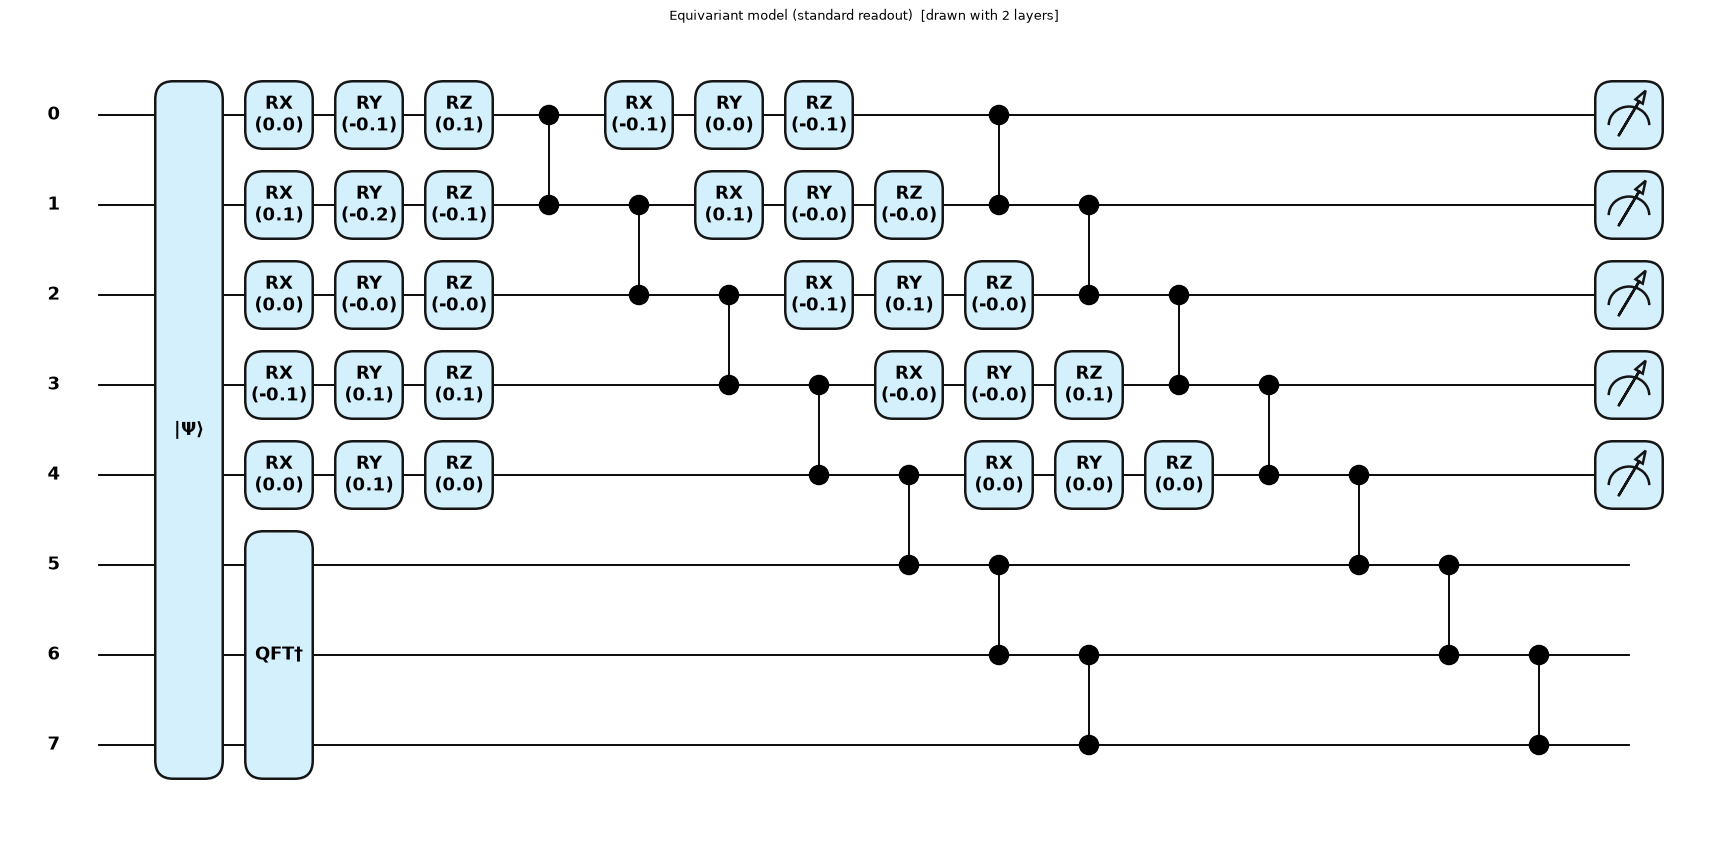

Equivariant model (standard readout)
   executed model: qubits = 8 (5 radial + 3 orbital), layers = 24, circuit depth = 126, gates = 530, trainable parameters = 360


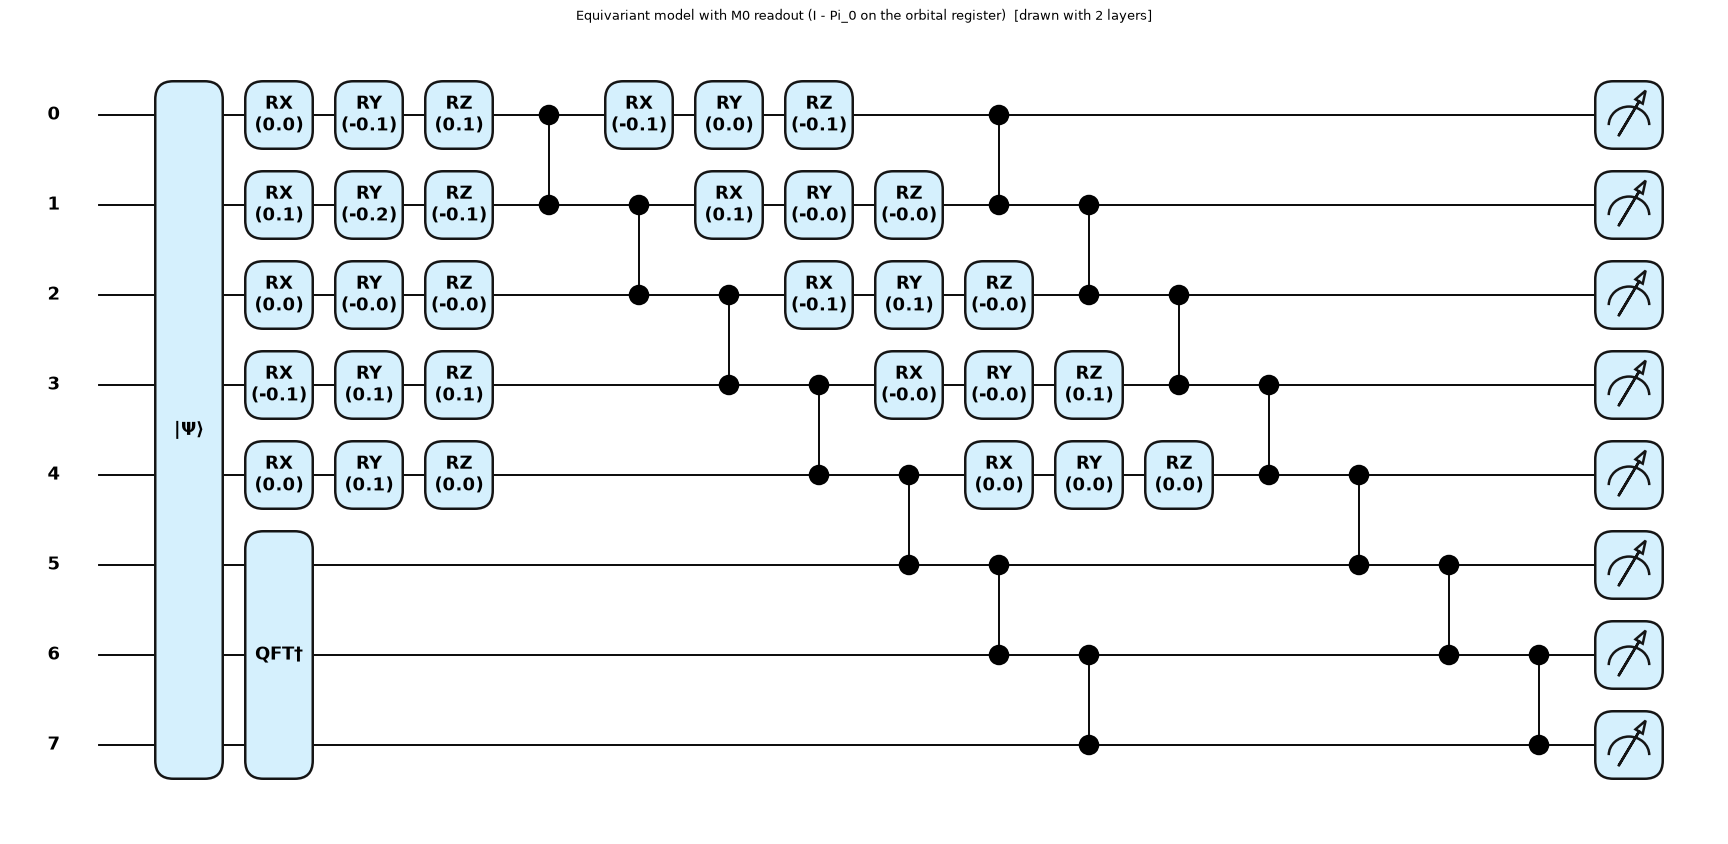

Equivariant model with M0 readout (I - Pi_0 on the orbital register)
   executed model: qubits = 8 (5 radial + 3 orbital), layers = 24, circuit depth = 126, gates = 530, trainable parameters = 360


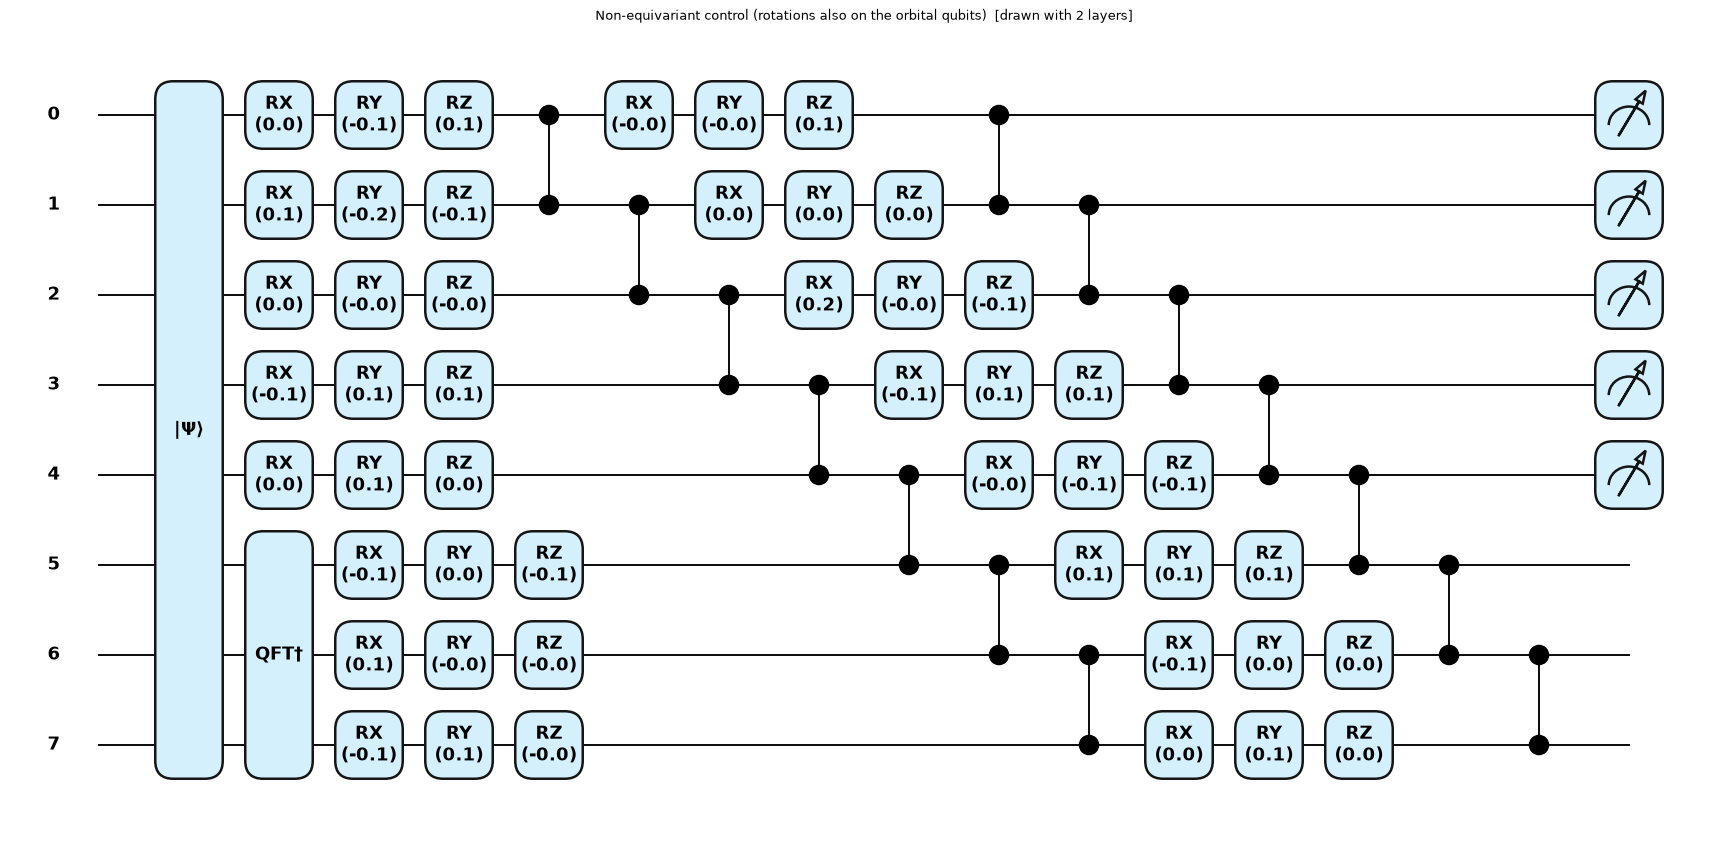

Non-equivariant control (rotations also on the orbital qubits)
   executed model: qubits = 8 (5 radial + 3 orbital), layers = 24, circuit depth = 126, gates = 746, trainable parameters = 576


In [10]:
DRAW_DEPTH = 2
def make_qnode(depth, n_classes, equivariant=True, m0=False):
    wires = list(range(N_QUBITS)); orb = list(range(N_RAD, N_QUBITS))
    rot_wires = list(range(N_RAD)) if equivariant else wires          # control also rotates orbital qubits
    dev = qml.device("default.qubit", wires=N_QUBITS)
    proj = np.diag([0.0] + [1.0] * (P - 1))                           # I - Pi_0 in the Fourier basis
    @qml.qnode(dev)
    def circuit(x, params):
        qml.StatePrep(x, wires=wires, normalize=True)                  # amplitude encoding of the polar samples
        qml.adjoint(qml.QFT)(wires=orb)                                # Fourier basis of Z_{N_phi} on the orbital register
        for l in range(depth):
            for i, w in enumerate(rot_wires):                          # trainable rotations
                qml.RX(params[l, i, 0], wires=w); qml.RY(params[l, i, 1], wires=w); qml.RZ(params[l, i, 2], wires=w)
            for w in range(N_QUBITS - 1):                              # nearest-neighbour CZ chain
                qml.CZ(wires=[w, w + 1])
        if m0:
            return [qml.expval(qml.PauliZ(j) @ qml.Hermitian(proj, wires=orb)) for j in range(n_classes)]
        return [qml.expval(qml.PauliZ(j)) for j in range(n_classes)]
    n_rot = len(rot_wires)
    return circuit, n_rot

C_DEMO = DATA[DATASETS[0]]["C"]
x_demo = DATA[DATASETS[0]]["X_tr"][0].double().numpy()
for title, kw in [("Equivariant model (standard readout)", dict(equivariant=True, m0=False)),
                  ("Equivariant model with M0 readout (I - Pi_0 on the orbital register)", dict(equivariant=True, m0=True)),
                  ("Non-equivariant control (rotations also on the orbital qubits)", dict(equivariant=False, m0=False))]:
    qn_d, n_rot = make_qnode(DRAW_DEPTH, C_DEMO, **kw)
    p_demo = np.random.default_rng(SEED).normal(0, INIT_STD, size=(DRAW_DEPTH, n_rot, 3))
    fig, ax = qml.draw_mpl(qn_d, decimals=1, style="pennylane")(x_demo, p_demo)
    fig.suptitle(title + f"  [drawn with {DRAW_DEPTH} layers]", fontsize=10, y=1.02); plt.show()
    qn_full, _ = make_qnode(DEPTH, C_DEMO, **kw)
    pf = np.random.default_rng(SEED).normal(0, INIT_STD, size=(DEPTH, n_rot, 3))
    res = qml.specs(qn_full, level="device")(x_demo, pf)
    rs = res["resources"] if isinstance(res, dict) else res.resources
    print(f"{title}\n   executed model: qubits = {N_QUBITS} ({N_RAD} radial + {N_ORB} orbital), layers = {DEPTH}, "
          f"circuit depth = {rs.depth}, gates = {rs.num_gates}, trainable parameters = {DEPTH * n_rot * 3}")

In [11]:
# ---- (1) the PyTorch simulator equals the PennyLane QNode (full executed depth, float64) ----
rg = np.random.default_rng(SEED + 1)
C_ = DATA[DATASETS[0]]["C"]
errs = []
for m0 in [False, True]:
    qn, n_rot = make_qnode(DEPTH, C_, equivariant=True, m0=m0)
    for t in range(3):
        xs = np.abs(rg.normal(size=R * P)) + 0.05
        pr = rg.uniform(-np.pi, np.pi, size=(DEPTH, n_rot, 3))
        ref = np.array(qn(xs, pr))
        w = torch.ones(1, P, dtype=torch.float64)
        if m0: w[0, 0] = 0
        sim = circuit_expvals(torch.tensor(pr[None]), torch.tensor(xs[None, None]), C_, w)[0, 0].numpy()
        errs.append(np.abs(ref - sim).max())
print("max |PennyLane - PyTorch simulator| over 6 random circuits/inputs (standard + M0 readout):", f"{max(errs):.2e}")
assert max(errs) < 1e-8, "simulator does not reproduce the PennyLane circuit"

# ---- (2) symmetry: rotating the image by g * 45 degrees = cyclic shift of phi. Equivariant circuit: output unchanged ----
xs = np.abs(rg.normal(size=(R, P))) + 0.05
rows = []
for equivariant in [True, False]:
    qn, n_rot = make_qnode(2, C_, equivariant=equivariant)
    pr = rg.uniform(-np.pi, np.pi, size=(2, n_rot, 3))
    base = np.array(qn(xs.ravel(), pr))
    for g in [1, 3, 5]:
        rolled = np.array(qn(np.roll(xs, g, axis=1).ravel(), pr))
        rows.append((("equivariant" if equivariant else "non-equivariant control"), g, np.abs(base - rolled).max()))
print(pd.DataFrame(rows, columns=["circuit", "rotation g (x45 deg)", "max |<Z_j>(x) - <Z_j>(R(g)x)|"]).to_string(index=False))
assert all(r[2] < 1e-10 for r in rows if r[0] == "equivariant") and all(r[2] > 1e-3 for r in rows if r[0] != "equivariant")

max |PennyLane - PyTorch simulator| over 6 random circuits/inputs (standard + M0 readout): 2.45e-11
                circuit  rotation g (x45 deg)  max |<Z_j>(x) - <Z_j>(R(g)x)|
            equivariant                     1                   2.220446e-16
            equivariant                     3                   2.775558e-16
            equivariant                     5                   2.220446e-16
non-equivariant control                     1                   5.791131e-03
non-equivariant control                     3                   5.791131e-03
non-equivariant control                     5                   5.791131e-03


## 4. Checking the feature-level theory numerically

Section III of the paper predicts that an equivariant model with invariant readout only sees the circular correlations $C_{r,r'}(\Delta\phi)$. We verify, on real images, that (i) $C$ is unchanged by rotating the image, (ii) T1 leaves $C$ unchanged although it visibly scrambles the ring samples, (iii) T3 changes $C$ only by the constant $N_\phi\,\bar x_r\bar x_{r'}$ (Eq. C5), and (iv) T2 destroys the correlation structure but keeps ring means. Finally we confirm that the *trained-model-independent* statement "output depends on $x$ only via its twirl" holds exactly for the simulator: random-parameter outputs for $x$ and for the T1-scrambled $x$ coincide up to float error.

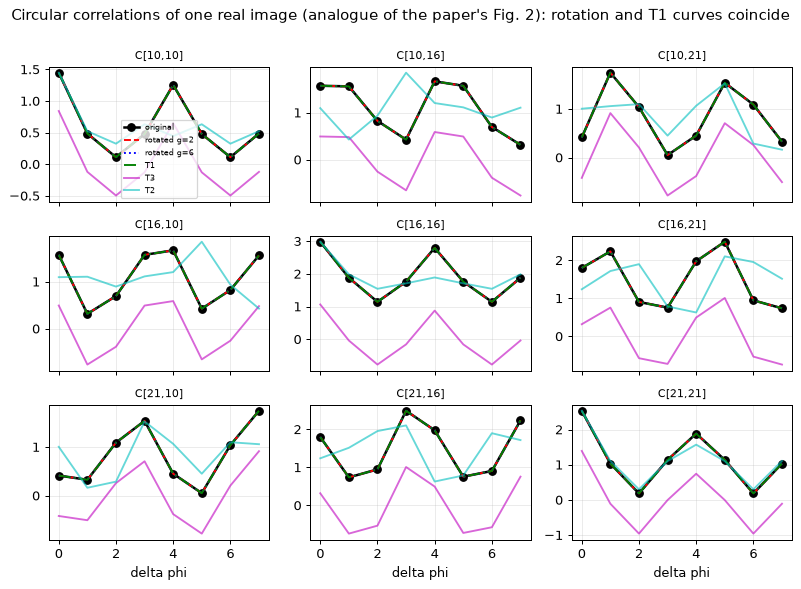

{'rotation g=2': 5.55e-17, 'rotation g=6': 5.55e-17, 'T1': 1.11e-07, 'T3 vs Eq.(C5)': 5.57e-08, 'T2 (should differ)': 1.42}
max |<Z>(x) - <Z>(T1 x)| with random parameters: 6.24e-09


In [12]:
def circ_corr(x, r, rp):
    """C_{r,r'}(dphi) = sum_a x[r,a] x[r',a-dphi] for dphi = 0..P-1 (x has shape (R,P))."""
    return np.array([np.sum(x[r] * np.roll(x[rp], dphi)) for dphi in range(P)])

d0 = DATA[DATASETS[0]]
x0 = d0["X_tr"][0].reshape(R, P).double().numpy()
x_t1 = t1_scramble(d0["X_tr"][:1], 5).reshape(R, P).double().numpy()
x_t2 = t2_permute(d0["X_tr"][:1], 5).reshape(R, P).double().numpy()
x_t3 = t3_demean(d0["X_tr"][:1]).reshape(R, P).double().numpy()
rings = [R // 3, R // 2, 2 * R // 3]
worst = {"rotation g=2": 0, "rotation g=6": 0, "T1": 0, "T3 vs Eq.(C5)": 0, "T2 (should differ)": 0}
fig, axs = plt.subplots(3, 3, figsize=(9, 6.5), sharex=True)
for a, r in enumerate(rings):
    for b, rp in enumerate(rings):
        C0 = circ_corr(x0, r, rp)
        for g in [2, 6]:
            worst[f"rotation g={g}"] = max(worst[f"rotation g={g}"], np.abs(circ_corr(np.roll(x0, g, 1), r, rp) - C0).max())
        worst["T1"] = max(worst["T1"], np.abs(circ_corr(x_t1, r, rp) - C0).max())
        const = P * x0[r].mean() * x0[rp].mean()
        worst["T3 vs Eq.(C5)"] = max(worst["T3 vs Eq.(C5)"], np.abs(circ_corr(x_t3, r, rp) - (C0 - const)).max())
        worst["T2 (should differ)"] = max(worst["T2 (should differ)"], np.abs(circ_corr(x_t2, r, rp) - C0).max())
        ax = axs[a, b]
        ax.plot(C0, "k-o", lw=2, label="original"); ax.plot(circ_corr(np.roll(x0, 2, 1), r, rp), "r--", label="rotated g=2")
        ax.plot(circ_corr(np.roll(x0, 6, 1), r, rp), "b:", label="rotated g=6"); ax.plot(circ_corr(x_t1, r, rp), "g-.", label="T1")
        ax.plot(circ_corr(x_t3, r, rp), "m-", alpha=0.6, label="T3"); ax.plot(circ_corr(x_t2, r, rp), "c-", alpha=0.6, label="T2")
        ax.set_title(f"C[{r},{rp}]", fontsize=9)
axs[0, 0].legend(fontsize=6); [ax.set_xlabel("delta phi") for ax in axs[-1]]
fig.suptitle("Circular correlations of one real image (analogue of the paper's Fig. 2): rotation and T1 curves coincide", y=1.0)
plt.tight_layout(); plt.show()
print({k: float(f"{v:.2e}") for k, v in worst.items()})
assert worst["rotation g=2"] < 1e-9 and worst["rotation g=6"] < 1e-9 and worst["T1"] < 1e-4 and worst["T3 vs Eq.(C5)"] < 1e-4 and worst["T2 (should differ)"] > 1e-3

# the model (random parameters, standard readout) cannot tell x from T1(x): same logits
pr = torch.randn(1, DEPTH, N_RAD, 3, dtype=torch.float64) * 1.0
xa = d0["X_te"][:16].double()[None]; xb_ = t1_scramble(d0["X_te"][:16], 3).double()[None]
la, lb = circuit_expvals(pr, xa, d0["C"]), circuit_expvals(pr, xb_, d0["C"])
print("max |<Z>(x) - <Z>(T1 x)| with random parameters:", f"{(la - lb).abs().max():.2e}")
assert (la - lb).abs().max() < 1e-4

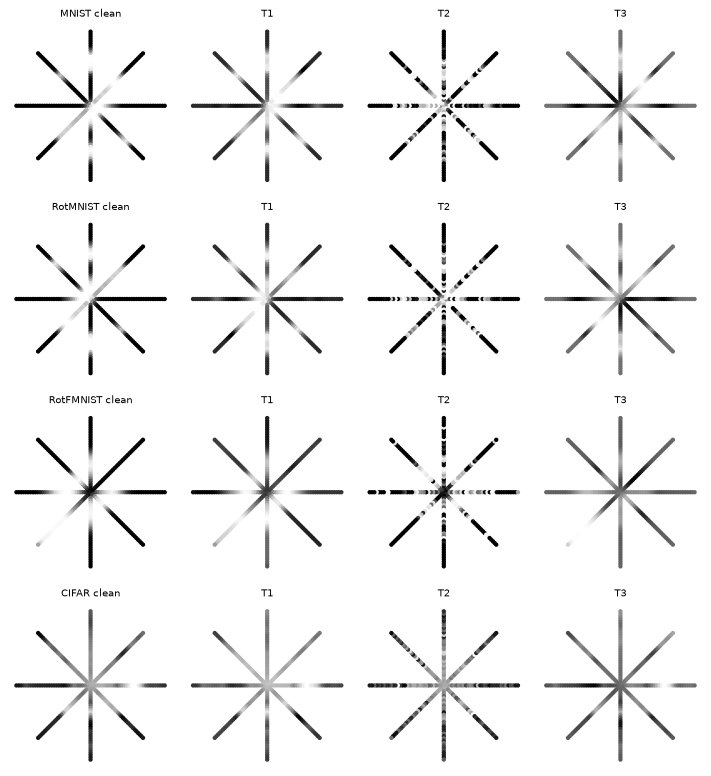

In [13]:
# analogue of the paper's Fig. 3: a clean sample and its T1, T2, T3 versions on the polar grid (values rescaled for display)
fig, axs = plt.subplots(len(DATA), 4, figsize=(8, 2.2 * len(DATA)))
axs = np.atleast_2d(axs)
for row, (name, d) in zip(axs, DATA.items()):
    for ax, tn in zip(row, ["clean", "T1", "T2", "T3"]):
        v = (d["X_tr"] if tn == "clean" else d[f"X_{tn}_tr"])[0].numpy()
        ax.scatter(PX, -PY, c=v, cmap="gray", s=12, edgecolors="none"); ax.set_aspect("equal"); ax.axis("off"); ax.set_facecolor("#7a7a7a")
        ax.set_title(f"{name} {tn}" if tn == "clean" else tn, fontsize=8)
plt.tight_layout(); plt.show()

## 5. Classical surrogates and the transfer attacks

The attacker never touches the quantum model. It trains a classical surrogate on the **clean** training split and crafts $\ell_\infty$ perturbations:

* **LC** (one linear layer) and **MLP** (one hidden layer of 256 ReLU units) work on the 256 ring samples in the same radial-orbital ordering as the quantum model; the perturbation lives in that space.
* **CNN** (three conv blocks with batch norm, ReLU, max-pooling, then a linear head) and **ResNet18** (torchvision architecture, single-channel stem) work on the 32 x 32 image; the perturbed image is then polar-sampled before it reaches the quantum model.
* FGSM: $x+\epsilon\,\mathrm{sign}(\nabla_x L)$; PGD: 10 steps of size $\alpha=\max(\epsilon/10,10^{-3})$ with projection onto the $\epsilon$-ball. Everything is clipped to the valid pixel range $[0,1]$.
* The surrogate checkpoint with the best accuracy on the **validation** split is used (the paper selects on the test set).

In [14]:
class Flat(nn.Module):
    def forward(self, x): return x.flatten(1)

def make_surrogate(kind, C):
    if kind == "LC":
        m = nn.Sequential(nn.Linear(R * P, C)); m.space = "feat"
    elif kind == "MLP":
        m = nn.Sequential(nn.Linear(R * P, 256), nn.ReLU(), nn.Linear(256, C)); m.space = "feat"
    elif kind == "CNN":
        def blk(i, o): return [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2)]
        m = nn.Sequential(*blk(1, 16), *blk(16, 32), *blk(32, 64), Flat(), nn.Linear(64 * (IMG // 8) ** 2, 128), nn.ReLU(), nn.Linear(128, C))
        m.space = "img"
    elif kind == "ResNet18":
        m = torchvision.models.resnet18(weights=None, num_classes=C)
        m.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False); m.space = "img"
    return m

def sur_input(m, d, tag, override=None):
    if m.space == "feat":
        return d["X_" + tag] if override is None else override
    return d["img_" + tag][:, None] if override is None else override

@torch.no_grad()
def acc_of(m, x, y, bs=500):
    m.eval(); n = 0
    for i in range(0, len(y), bs):
        n += (m(x[i:i + bs]).argmax(1) == y[i:i + bs]).sum().item()
    return n / len(y)

def train_surrogate(kind, d, seed):
    torch.manual_seed(seed)
    m = make_surrogate(kind, d["C"]); opt = torch.optim.AdamW(m.parameters(), lr=SUR_LR, weight_decay=1e-4)
    xtr, ytr = sur_input(m, d, "tr"), d["y_tr"]; xva = sur_input(m, d, "va")
    best, best_sd = -1, None; g = torch.Generator().manual_seed(seed)
    for ep in range(SUR_EPOCHS[kind]):
        m.train(); perm = torch.randperm(len(ytr), generator=g)
        for i in range(0, len(ytr), 128):
            idx = perm[i:i + 128]
            if len(idx) < 2: continue
            opt.zero_grad(); F.cross_entropy(m(xtr[idx]), ytr[idx]).backward(); opt.step()
        a = acc_of(m, xva, d["y_va"])
        if a > best: best, best_sd = a, copy.deepcopy(m.state_dict())
    m.load_state_dict(best_sd); m.eval()
    return m

def fgsm(m, x, y, eps):
    """eps: float or tensor broadcastable to x"""
    x = x.clone().requires_grad_(True)
    g, = torch.autograd.grad(F.cross_entropy(m(x), y), x)
    return (x.detach() + eps * g.sign()).clamp(0, 1)

def pgd(m, x, y, eps, steps=PGD_STEPS):
    if eps == 0: return x.clone()
    alpha = max(eps / steps, 1e-3); xa = x.clone()
    for _ in range(steps):
        xa.requires_grad_(True)
        g, = torch.autograd.grad(F.cross_entropy(m(xa), y), xa)
        xa = xa.detach() + alpha * g.sign()
        xa = torch.min(torch.max(xa, x - eps), x + eps).clamp(0, 1)
    return xa.detach()

def attack_to_features(m, d, eps, kind="PGD"):
    """craft adversarial test examples on surrogate m; return (white-box accuracy, features fed to the quantum model)."""
    n = len(d["y_te"]) if m.space == "feat" else min(N_ATTACK_IMG, len(d["y_te"]))
    x, y = sur_input(m, d, "te")[:n], d["y_te"][:n]
    xa = pgd(m, x, y, eps) if kind == "PGD" else fgsm(m, x, y, eps)
    wb = acc_of(m, xa, y)
    feats = xa if m.space == "feat" else polar_encode(xa[:, 0])
    return wb, feats

SUR_KINDS = ["LC", "MLP", "CNN", "ResNet18"]
SURS = {}
t0 = time.time()
for name, d in DATA.items():
    SURS[name] = {}
    for k in SUR_KINDS:
        SURS[name][k] = train_surrogate(k, d, SEED)
    print(f"{name:10s} clean test accuracy of the surrogates:",
          {k: round(acc_of(m, sur_input(m, d, "te"), d["y_te"]), 3) for k, m in SURS[name].items()}, f"({time.time()-t0:.0f}s)")

MNIST      clean test accuracy of the surrogates: {'LC': 0.95, 'MLP': 0.976, 'CNN': 0.998, 'ResNet18': 0.988} (330s)


RotMNIST   clean test accuracy of the surrogates: {'LC': 0.728, 'MLP': 0.874, 'CNN': 0.938, 'ResNet18': 0.928} (923s)


RotFMNIST  clean test accuracy of the surrogates: {'LC': 0.676, 'MLP': 0.74, 'CNN': 0.808, 'ResNet18': 0.736} (1313s)


CIFAR      clean test accuracy of the surrogates: {'LC': 0.684, 'MLP': 0.766, 'CNN': 0.904, 'ResNet18': 0.888} (1660s)


**Adversarial training set.** As in the paper (Appendix D d), for each dataset a random 50% of the training images is replaced by an FGSM example crafted on the LC surrogate with a per-image $\epsilon\sim U[0.05,0.2]$; the other 50% stays clean. Labels are unchanged. The validation split used for checkpoint selection stays clean.

In [15]:
for name, d in DATA.items():
    g = torch.Generator().manual_seed(SEED + 5)
    n = len(d["y_tr"]); sel = torch.randperm(n, generator=g)[: n // 2]
    eps = (0.05 + 0.15 * torch.rand(len(sel), 1, generator=g))
    lc = SURS[name]["LC"]
    Xadv = d["X_tr"].clone(); Xadv[sel] = fgsm(lc, d["X_tr"][sel], d["y_tr"][sel], eps)
    d["X_adv_tr"] = Xadv
    print(f"{name}: {len(sel)} of {n} training images replaced by FGSM(LC) examples, mean |delta|_inf = {(Xadv[sel]-d['X_tr'][sel]).abs().amax(1).mean():.3f}")

MNIST: 1000 of 2000 training images replaced by FGSM(LC) examples, mean |delta|_inf = 0.126


RotMNIST: 1000 of 2000 training images replaced by FGSM(LC) examples, mean |delta|_inf = 0.126
RotFMNIST: 1000 of 2000 training images replaced by FGSM(LC) examples, mean |delta|_inf = 0.126
CIFAR: 1000 of 2000 training images replaced by FGSM(LC) examples, mean |delta|_inf = 0.126


## 6. Training the quantum models

For every dataset we train, **at once**, `len(VARIANTS) x SEEDS` independent models (one per row of the batch):

| variant | training data | readout |
|---|---|---|
| clean | clean images | standard |
| T1 / T2 / T3 | the same images after transformation T1 / T2 / T3 | standard |
| adv | 50% clean + 50% FGSM(LC) | standard |
| M0 | clean images | $Z_j\otimes(I-\Pi_0)$ (m = 0 sector removed) |

Models of the same seed share their initial parameters and the order of the mini-batches (paired comparison). Adam on the sum of the per-model cross-entropy losses (the models are independent, so this is exactly one Adam run per model); after every epoch the validation accuracy of each model is computed and the **best-validation parameters** of each model are kept ("best weights" in the paper).

In [16]:
def variant_inputs(d, v):
    return {"clean": d["X_tr"], "T1": d["X_T1_tr"], "T2": d["X_T2_tr"], "T3": d["X_T3_tr"], "adv": d["X_adv_tr"], "M0": d["X_tr"]}[v]

def model_index(v, s): return VARIANTS.index(v) * SEEDS + s
M_TOTAL = len(VARIANTS) * SEEDS

def sector_weights():
    w = torch.ones(M_TOTAL, P)
    for s in range(SEEDS): w[model_index("M0", s), 0] = 0.0
    return w
M0W = sector_weights()

@torch.no_grad()
def q_logits(params, X, C, m0w, idx=None, chunk=100):
    """expectation values <Z_j> for models `idx` (default all) on shared inputs X (N,R*P) -> (len(idx), N, C)."""
    idx = list(range(params.shape[0])) if idx is None else list(idx)
    outs = []
    for i in range(0, X.shape[0], chunk):
        xb = X[i:i + chunk][None].expand(len(idx), -1, -1)
        outs.append(circuit_expvals(params[idx], xb, C, m0w[idx]))
    return torch.cat(outs, 1)

def q_accuracy(params, X, y, C, idx=None):
    return (q_logits(params, X, C, M0W, idx).argmax(-1) == y[None]).float().mean(1)

def train_quantum(d):
    C, N = d["C"], len(d["y_tr"])
    params = torch.zeros(M_TOTAL, DEPTH, N_RAD, 3)
    for v in VARIANTS:
        for s in range(SEEDS):
            g = torch.Generator().manual_seed(SEED * 1000 + s)
            params[model_index(v, s)] = INIT_STD * torch.randn(DEPTH, N_RAD, 3, generator=g)
    params.requires_grad_(True)
    opt = torch.optim.Adam([params], lr=LR)
    Xv = torch.stack([variant_inputs(d, v) for v in VARIANTS])            # (V,N,dim)
    gens = [torch.Generator().manual_seed(SEED + 31 * s) for s in range(SEEDS)]
    best = params.detach().clone(); best_acc = torch.full((M_TOTAL,), -1.0)
    hist_loss, hist_val = [], []
    steps = N // BATCH
    for ep in range(EPOCHS):
        perms = torch.stack([torch.randperm(N, generator=g) for g in gens])      # (S,N)
        tot = torch.zeros(M_TOTAL)
        for st in range(steps):
            idx = perms[:, st * BATCH:(st + 1) * BATCH]                          # (S,B)
            xb = Xv[:, idx]                                                       # (V,S,B,dim)
            xb = xb.reshape(M_TOTAL, BATCH, -1)
            yb = d["y_tr"][idx][None].expand(len(VARIANTS), -1, -1).reshape(M_TOTAL, BATCH)
            ex = circuit_expvals(params, xb, C, M0W)
            loss_m = F.cross_entropy((TEMP * ex).reshape(-1, C), yb.reshape(-1), reduction="none").reshape(M_TOTAL, BATCH).mean(1)
            opt.zero_grad(); loss_m.sum().backward(); opt.step()
            tot += loss_m.detach()
        va = q_accuracy(params.detach(), d["X_va"], d["y_va"], C)
        better = va > best_acc; best_acc = torch.where(better, va, best_acc)
        best[better] = params.detach()[better]
        hist_loss.append((tot / steps).numpy()); hist_val.append(va.numpy())
        print(f"   epoch {ep+1}/{EPOCHS}  mean train loss {float((tot/steps).mean()):.3f}  mean val acc {float(va.mean()):.3f}  "
              f"(best-so-far mean {float(best_acc.mean()):.3f})")
    return best, np.array(hist_loss), np.array(hist_val)

QP, HIST = {}, {}
TRAIN_TIME = {}
for name, d in DATA.items():
    cache = os.path.join(DATA_DIR, f"qparams_{name}_{'fast' if FAST_MODE else 'full'}_D{DEPTH}_S{SEEDS}_E{EPOCHS}_N{N_TRAIN}.pt")
    t0 = time.time()
    if os.path.exists(cache):
        blob = torch.load(cache); QP[name], HIST[name] = blob["p"], blob["h"]; print(name, "loaded cached parameters")
    else:
        print(f"training {M_TOTAL} models on {name} ({len(VARIANTS)} variants x {SEEDS} seeds, depth {DEPTH}, {N_TRAIN} images)")
        p, hl, hv = train_quantum(d); QP[name], HIST[name] = p, {"loss": hl, "val": hv}
        torch.save({"p": p, "h": HIST[name]}, cache)
    TRAIN_TIME[name] = time.time() - t0
    print(f"{name}: done in {TRAIN_TIME[name]/60:.1f} min")

training 18 models on MNIST (6 variants x 3 seeds, depth 24, 2000 images)


   epoch 1/8  mean train loss 1.222  mean val acc 0.546  (best-so-far mean 0.546)


   epoch 2/8  mean train loss 0.989  mean val acc 0.569  (best-so-far mean 0.584)


   epoch 3/8  mean train loss 0.935  mean val acc 0.593  (best-so-far mean 0.602)


   epoch 4/8  mean train loss 0.885  mean val acc 0.624  (best-so-far mean 0.629)


...

   epoch 4/8  mean train loss 0.602  mean val acc 0.620  (best-so-far mean 0.641)


   epoch 5/8  mean train loss 0.596  mean val acc 0.632  (best-so-far mean 0.643)


   epoch 6/8  mean train loss 0.595  mean val acc 0.618  (best-so-far mean 0.643)


   epoch 7/8  mean train loss 0.593  mean val acc 0.624  (best-so-far mean 0.648)


   epoch 8/8  mean train loss 0.589  mean val acc 0.619  (best-so-far mean 0.651)
CIFAR: done in 3.5 min


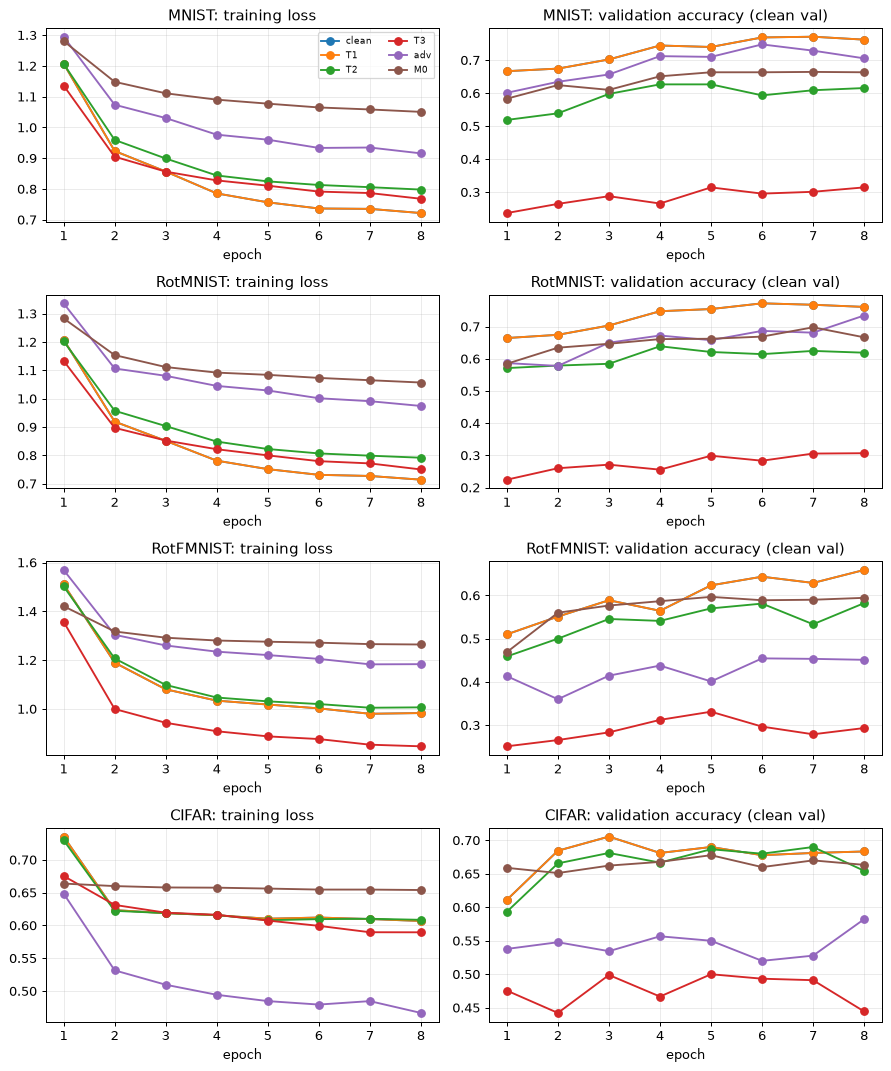

In [17]:
# training curves (mean over seeds) per variant
fig, axs = plt.subplots(len(DATA), 2, figsize=(10, 3 * len(DATA)), squeeze=False)
for row, (name, d) in zip(axs, DATA.items()):
    for v in VARIANTS:
        ids = [model_index(v, s) for s in range(SEEDS)]
        row[0].plot(np.arange(1, EPOCHS + 1), HIST[name]["loss"][:, ids].mean(1), marker="o", label=v)
        row[1].plot(np.arange(1, EPOCHS + 1), HIST[name]["val"][:, ids].mean(1), marker="o", label=v)
    row[0].set_title(f"{name}: training loss"); row[1].set_title(f"{name}: validation accuracy (clean val)")
    row[0].set_xlabel("epoch"); row[1].set_xlabel("epoch")
axs[0, 0].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

## 7. Which rotation-invariant statistics does the model use? (Table I)

*(a)* models trained on clean data are evaluated on T1/T2/T3-transformed test sets; *(b)* models trained on T1/T2/T3 data are evaluated on the clean test set. Values are mean test accuracy over seeds (± standard deviation); the number in brackets is the change relative to the clean baseline of the same dataset. T1 is a built-in sanity check: because T1 only acts in the subspace the model cannot see, accuracy must be identical.

In [18]:
TAB = {}   # TAB[name]["a"/"b"][label] -> (mean, std) ; per-seed arrays kept too
for name, d in DATA.items():
    C = d["C"]; ids_clean = [model_index("clean", s) for s in range(SEEDS)]
    a, b = {}, {}
    a["Clean"] = q_accuracy(QP[name], d["X_te"], d["y_te"], C, ids_clean).numpy()
    for tn in ["T1", "T2", "T3"]:
        a[tn] = q_accuracy(QP[name], d[f"X_{tn}_te"], d["y_te"], C, ids_clean).numpy()
    b["Clean"] = a["Clean"]
    for tn in ["T1", "T2", "T3"]:
        ids = [model_index(tn, s) for s in range(SEEDS)]
        b[tn] = q_accuracy(QP[name], d["X_te"], d["y_te"], C, ids).numpy()
    TAB[name] = {"a": a, "b": b}
    # exactness of the T1 statement: logits identical (not only accuracy)
    l0 = q_logits(QP[name], d["X_te"], C, M0W, ids_clean); l1 = q_logits(QP[name], d["X_T1_te"], C, M0W, ids_clean)
    TAB[name]["t1_logit_gap"] = float((l0 - l1).abs().max())

def fmt(arr, ref):
    return f"{arr.mean():.2f}±{arr.std():.2f} ({arr.mean()-ref.mean():+.2f})"
for panel, title in [("a", "(a) train on clean, test on transformed data"), ("b", "(b) train on transformed data, test on clean")]:
    df = pd.DataFrame({name: {k: fmt(v, TAB[name][panel]["Clean"]) for k, v in TAB[name][panel].items()} for name in DATA})
    print(title); print(df.to_string()); print()
print("max |logit(x) - logit(T1 x)| for clean-trained models:", {n: f"{TAB[n]['t1_logit_gap']:.1e}" for n in DATA})

(a) train on clean, test on transformed data
                   MNIST           RotMNIST          RotFMNIST              CIFAR
Clean  0.76±0.01 (+0.00)  0.77±0.01 (+0.00)  0.65±0.01 (+0.00)  0.68±0.01 (+0.00)
T1     0.76±0.01 (+0.00)  0.77±0.01 (+0.00)  0.65±0.01 (+0.00)  0.68±0.01 (+0.00)
T2     0.63±0.03 (-0.12)  0.66±0.03 (-0.10)  0.62±0.01 (-0.03)  0.66±0.02 (-0.01)
T3     0.44±0.03 (-0.32)  0.44±0.04 (-0.32)  0.39±0.03 (-0.26)  0.65±0.01 (-0.03)

(b) train on transformed data, test on clean
                   MNIST           RotMNIST          RotFMNIST              CIFAR
Clean  0.76±0.01 (+0.00)  0.77±0.01 (+0.00)  0.65±0.01 (+0.00)  0.68±0.01 (+0.00)
T1     0.76±0.01 (+0.00)  0.77±0.01 (+0.00)  0.65±0.01 (+0.00)  0.68±0.01 (+0.00)
T2     0.61±0.02 (-0.15)  0.63±0.01 (-0.13)  0.63±0.01 (-0.02)  0.68±0.01 (-0.00)
T3     0.35±0.04 (-0.41)  0.33±0.04 (-0.44)  0.34±0.05 (-0.31)  0.50±0.00 (-0.18)

max |logit(x) - logit(T1 x)| for clean-trained models: {'MNIST': '4.2e-07', 'RotMNIST': 

## 8. Transfer robustness against the LC and MLP surrogates (Figure 4)

PGD examples crafted on the clean-trained LC (top) and MLP (bottom) surrogates, applied to the quantum models trained on clean, T3 and T2 data. The grey dashed curve is the surrogate's own *white-box* accuracy. Curves are means over seeds (shaded: ± one standard deviation) on the test images. All adversarial inputs are in the clean-image domain (the T-trained models are not given a transformed version of the attack).

MNIST: transfer evaluation done (138s)


RotMNIST: transfer evaluation done (275s)


RotFMNIST: transfer evaluation done (418s)


CIFAR: transfer evaluation done (556s)


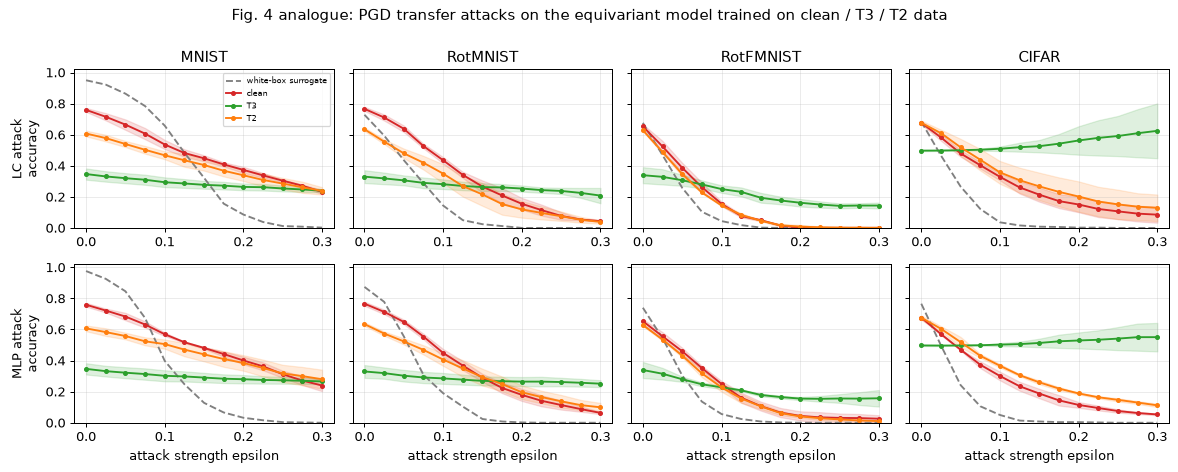

In [19]:
EPS_OF = {sk: (EPS_GRID if sk in ("LC", "MLP") else EPS_GRID[::IMG_EPS_STRIDE]) for sk in ["LC", "MLP", "CNN", "ResNet18"]}
RESULTS = {n: {"curves": {}, "white": {}} for n in DATA}
t0 = time.time()
for name, d in DATA.items():
    C = d["C"]
    for sk in SUR_KINDS:
        wbs, feats_by_eps = [], []
        for e in EPS_OF[sk]:
            wb, ft = attack_to_features(SURS[name][sk], d, e, "PGD"); wbs.append(wb); feats_by_eps.append(ft)
        RESULTS[name]["white"][sk] = np.array(wbs)
        want = VARIANTS if sk in ("LC", "MLP") else ["clean", "adv", "M0"]       # Fig.4 uses LC/MLP, Fig.5 all four
        for v in want:
            ids = [model_index(v, s) for s in range(SEEDS)]
            RESULTS[name]["curves"][(sk, v)] = np.stack([q_accuracy(QP[name], ft, d["y_te"][:len(ft)], C, ids).numpy() for ft in feats_by_eps], 1)  # (S, n_eps)
    print(f"{name}: transfer evaluation done ({time.time()-t0:.0f}s)")

def curve_plot(variants_colors, surs, fname_title):
    fig, axs = plt.subplots(len(surs), len(DATA), figsize=(3.3 * len(DATA), 2.6 * len(surs)), squeeze=False, sharey=True)
    for i, sk in enumerate(surs):
        for j, name in enumerate(DATA):
            ax = axs[i, j]
            ax.plot(EPS_OF[sk], RESULTS[name]["white"][sk], "--", color="gray", label="white-box surrogate")
            for v, col in variants_colors.items():
                arr = RESULTS[name]["curves"][(sk, v)]
                ax.plot(EPS_OF[sk], arr.mean(0), color=col, marker="o", ms=3, label=v)
                ax.fill_between(EPS_OF[sk], arr.mean(0) - arr.std(0), arr.mean(0) + arr.std(0), color=col, alpha=0.15)
            ax.set_ylim(0, 1.02)
            if i == 0: ax.set_title(name)
            if j == 0: ax.set_ylabel(f"{sk} attack\naccuracy")
            if i == len(surs) - 1: ax.set_xlabel("attack strength epsilon")
    axs[0, 0].legend(fontsize=6)
    fig.suptitle(fname_title, y=1.0); plt.tight_layout(); plt.show()

curve_plot({"clean": "tab:red", "T3": "tab:green", "T2": "tab:orange"}, ["LC", "MLP"],
           "Fig. 4 analogue: PGD transfer attacks on the equivariant model trained on clean / T3 / T2 data")

## 9. Adversarial training and the m = 0 readout projection (Figure 5)

Same attacks, now for four surrogates (LC, MLP, CNN, ResNet18) and the models trained with adversarial examples (**adv**) or trained on clean data with the $m=0$ Fourier sector removed at the readout (**M0**), against the clean-trained baseline. The paper's claim is that M0 improves robustness for every surrogate while keeping more clean accuracy than adversarial training.

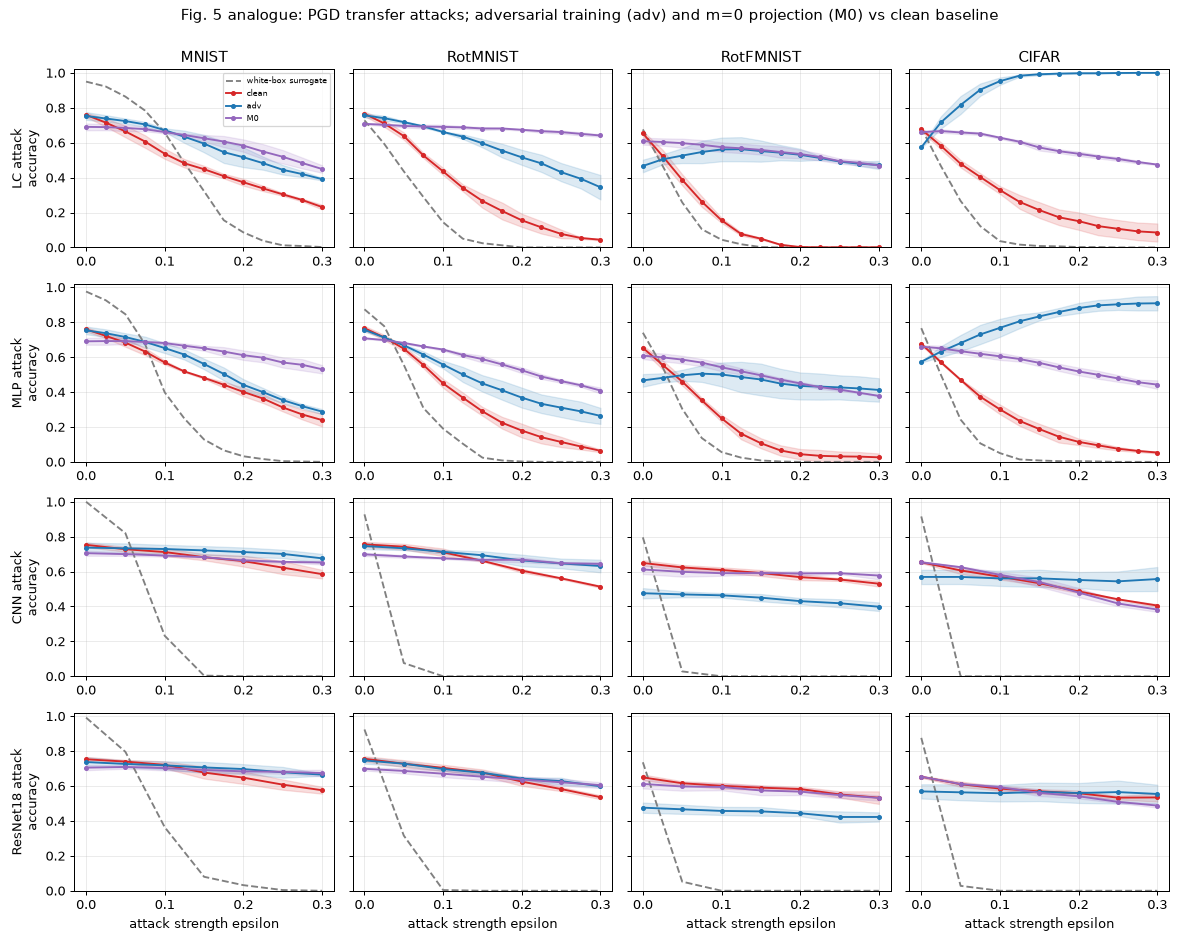

In [20]:
curve_plot({"clean": "tab:red", "adv": "tab:blue", "M0": "tab:purple"}, SUR_KINDS,
           "Fig. 5 analogue: PGD transfer attacks; adversarial training (adv) and m=0 projection (M0) vs clean baseline")

## 10. Ring-invariance of the linear surrogate (Appendix F, Table III)

A linear classifier gives rotation-invariant predictions if its weights are constant along each ring, i.e. depend only on the ring-averaged intensities. The score $S_{ring}=1-\|W-\Pi_{ring}W\|_F/\|W\|_F$ measures how close the learned weights are to that subspace ($\Pi_{ring}$ averages the weights of each ring over $\phi$). The paper reports higher scores for the rotationally augmented datasets.

In [21]:
SRING = {}
for name in DATA:
    W = SURS[name]["LC"][0].weight.detach().reshape(-1, R, P)
    Wp = W.mean(-1, keepdim=True).expand_as(W)
    SRING[name] = float(1 - (W - Wp).norm() / W.norm())
print(pd.Series(SRING, name="S_ring (this notebook)").round(3).to_string())

MNIST        0.138
RotMNIST     0.516
RotFMNIST    0.577
CIFAR        0.163


## 11. Side-by-side comparison with the paper

Paper numbers are read from Table I, Table III and the qualitative statements about Figures 4-5 (the figure curves themselves are not tabulated). Tolerance for a numeric claim: 0.02 accuracy points (0.02 in $S_{ring}$); a qualitative claim is *reproduced* when its inequality holds here by more than 0.02 where a margin is needed. Because our model is much smaller (8 qubits, 5 classes, 16-fold shallower budget, fewer seeds), absolute accuracies are not expected to match; the verdicts say so plainly. STM cannot be checked (no public data).

In [22]:
PAPER_A = {   # Table I(a): train clean, test on T
    "MNIST":     {"Clean": .84, "T1": .84, "T2": .35, "T3": .55},
    "RotMNIST":  {"Clean": .85, "T1": .85, "T2": .37, "T3": .50},
    "RotFMNIST": {"Clean": .72, "T1": .72, "T2": .42, "T3": .43},
    "CIFAR":     {"Clean": .76, "T1": .76, "T2": .69, "T3": .72}}
PAPER_B = {   # Table I(b): train on T, test clean
    "MNIST":     {"Clean": .84, "T1": .85, "T2": .59, "T3": .71},
    "RotMNIST":  {"Clean": .85, "T1": .85, "T2": .59, "T3": .72},
    "RotFMNIST": {"Clean": .72, "T1": .72, "T2": .56, "T3": .54},
    "CIFAR":     {"Clean": .76, "T1": .76, "T2": .70, "T3": .67}}
PAPER_SRING = {"CIFAR": .127, "MNIST": .162, "RotFMNIST": .401, "RotMNIST": .306, "STM": .463}
TOL = 0.02

def verdict_num(paper, ours, tol=TOL):
    if abs(ours - paper) <= tol: return "reproduced"
    return "exceeded" if ours > paper else "not reached"

rows = []
for name in DATA:
    A, B = TAB[name]["a"], TAB[name]["b"]
    rows.append((name, "clean test accuracy (Table I)", PAPER_A[name]["Clean"], A["Clean"].mean(), verdict_num(PAPER_A[name]["Clean"], A["Clean"].mean())))
    for tn in ["T1", "T2", "T3"]:
        pa = PAPER_A[name][tn] - PAPER_A[name]["Clean"]; oa = A[tn].mean() - A["Clean"].mean()
        pb = PAPER_B[name][tn] - PAPER_B[name]["Clean"]; ob = B[tn].mean() - B["Clean"].mean()
        rows.append((name, f"(a) change when testing on {tn}", pa, oa, verdict_num(pa, oa)))
        rows.append((name, f"(b) change when training on {tn}", pb, ob, verdict_num(pb, ob)))
df_num = pd.DataFrame(rows, columns=["dataset", "claim", "paper", "this notebook", "verdict"])
df_num[["paper", "this notebook"]] = df_num[["paper", "this notebook"]].round(3)
print(df_num.to_string(index=False))

  dataset                          claim  paper  this notebook     verdict
    MNIST  clean test accuracy (Table I)   0.84          0.759 not reached
    MNIST  (a) change when testing on T1   0.00          0.000  reproduced
    MNIST (b) change when training on T1   0.01          0.000  reproduced
    MNIST  (a) change when testing on T2  -0.49         -0.125    exceeded
    MNIST (b) change when training on T2  -0.25         -0.152    exceeded
    MNIST  (a) change when testing on T3  -0.29         -0.319 not reached
    MNIST (b) change when training on T3  -0.13         -0.413 not reached
 RotMNIST  clean test accuracy (Table I)   0.85          0.766 not reached
 RotMNIST  (a) change when testing on T1   0.00          0.000  reproduced
 RotMNIST (b) change when training on T1   0.00          0.000  reproduced
 RotMNIST  (a) change when testing on T2  -0.48         -0.101    exceeded
 RotMNIST (b) change when training on T2  -0.26         -0.131    exceeded
 RotMNIST  (a) change whe

In [23]:
# qualitative claims -------------------------------------------------------------------------------
def rob(name, sk, v, e_min=0.05):
    arr = RESULTS[name]["curves"][(sk, v)]                     # (S, n_eps)
    keep = [i for i, e in enumerate(EPS_OF[sk]) if e >= e_min]
    return float(arr[:, keep].mean())
def clean_acc(name, v):
    d = DATA[name]; ids = [model_index(v, s) for s in range(SEEDS)]
    return float(q_accuracy(QP[name], d["X_te"], d["y_te"], d["C"], ids).mean())

q = []
def add(claim, name, paper, ours, ok, extra=""):
    q.append((claim, name, paper, ours, "reproduced" if ok else "not reached here", extra))

for name in DATA:
    A, B = TAB[name]["a"], TAB[name]["b"]
    # Table I qualitative: T1 is exactly neutral
    add("T1 leaves the model unchanged (logits identical)", name, "identical accuracy", f"max logit gap {TAB[name]['t1_logit_gap']:.1e}",
        TAB[name]["t1_logit_gap"] < 1e-3 and abs(A['T1'].mean() - A['Clean'].mean()) < 1e-9)
    # which statistic carries more of the signal when TRAINING on it (b): T3 > T2 for MNIST/RotMNIST, T2 >= T3 elsewhere
    paper_t3_better = PAPER_B[name]["T3"] > PAPER_B[name]["T2"]
    ours_t3_better = B["T3"].mean() > B["T2"].mean()
    add("Table I(b): which transformation keeps more usable signal", name, "T3 > T2" if paper_t3_better else "T2 >= T3",
        "T3 > T2" if ours_t3_better else "T2 >= T3", paper_t3_better == ours_t3_better)
    # robustness claims (Fig. 4): mean accuracy over eps in [0.05, 0.3]
    for sk in ["LC", "MLP"]:
        c, t3, t2 = rob(name, sk, "clean"), rob(name, sk, "T3"), rob(name, sk, "T2")
        add(f"Fig.4 {sk}: T3-trained more robust than clean", name, "yes", f"{t3:.2f} vs {c:.2f}", t3 > c + TOL)
        add(f"Fig.4 {sk}: T2-trained not more robust than clean", name, "yes", f"{t2:.2f} vs {c:.2f}", t2 <= c + TOL)
    # Fig. 5
    add("Fig.5 LC: adversarial training improves robustness", name, "yes", f"{rob(name,'LC','adv'):.2f} vs {rob(name,'LC','clean'):.2f}",
        rob(name, "LC", "adv") > rob(name, "LC", "clean") + TOL)
    for sk in SUR_KINDS:
        add(f"Fig.5 {sk}: M0 projection improves robustness", name, "yes", f"{rob(name,sk,'M0'):.2f} vs {rob(name,sk,'clean'):.2f}",
            rob(name, sk, "M0") > rob(name, sk, "clean") + TOL)
    cl, ad, m0 = clean_acc(name, "clean"), clean_acc(name, "adv"), clean_acc(name, "M0")
    add("M0 keeps more clean accuracy than adversarial training", name, "yes", f"clean {cl:.2f}, adv {ad:.2f}, M0 {m0:.2f}", (cl - m0) < (cl - ad) - 1e-9 or m0 >= ad)
    # equivariance alone is not robust: clean-trained model collapses under LC transfer at eps=0.1
    i01 = EPS_GRID.index(0.1) if 0.1 in EPS_GRID else int(np.argmin(np.abs(np.array(EPS_GRID) - 0.1)))
    a0, a1 = RESULTS[name]["curves"][("LC", "clean")][:, 0].mean(), RESULTS[name]["curves"][("LC", "clean")][:, i01].mean()
    add("Equivariance alone is not robust (LC transfer at eps=0.1 hurts the clean-trained model)", name, "large drop", f"{a0:.2f} -> {a1:.2f}", a0 - a1 > 0.10)
for name in DATA:
    add("Table III: S_ring of the learned LC", name, PAPER_SRING[name], f"{SRING[name]:.3f}", abs(SRING[name] - PAPER_SRING[name]) <= TOL)
paper_rot_higher = PAPER_SRING["RotMNIST"] > PAPER_SRING["MNIST"]
if "RotMNIST" in SRING and "MNIST" in SRING:
    add("Table III: rotation-augmented data give a more ring-invariant LC (RotMNIST > MNIST)", "RotMNIST/MNIST", "yes", f"{SRING['RotMNIST']:.3f} vs {SRING['MNIST']:.3f}", SRING["RotMNIST"] > SRING["MNIST"])
q.append(("Everything on STM (10 classes, 128x128 STM images)", "STM", "-", "-", "cannot be checked", "no public data"))
df_q = pd.DataFrame(q, columns=["claim", "dataset", "paper", "this notebook", "verdict", "note"])
pd.set_option("display.width", 220, "display.max_colwidth", 80)
print(df_q.drop(columns="note").to_string(index=False))
n_ok = int((df_q.verdict == "reproduced").sum()); n_all = int((df_q.verdict != "cannot be checked").sum())
n_ok_num = int((df_num.verdict == "reproduced").sum())
print(f"\nqualitative claims reproduced: {n_ok}/{n_all}; numeric claims within {TOL}: {n_ok_num}/{len(df_num)}")

                                                                                  claim        dataset              paper                 this notebook           verdict
                                       T1 leaves the model unchanged (logits identical)          MNIST identical accuracy         max logit gap 4.2e-07        reproduced
                              Table I(b): which transformation keeps more usable signal          MNIST            T3 > T2                      T2 >= T3  not reached here
                                            Fig.4 LC: T3-trained more robust than clean          MNIST                yes                  0.28 vs 0.42  not reached here
                                        Fig.4 LC: T2-trained not more robust than clean          MNIST                yes                  0.38 vs 0.42        reproduced
                                           Fig.4 MLP: T3-trained more robust than clean          MNIST                yes                  0.29 vs 0.4

In [24]:
# compact numeric summary for the manifest / report
summary = {n: dict(clean=round(float(TAB[n]['a']['Clean'].mean()), 3),
                   a_T2=round(float(TAB[n]['a']['T2'].mean()), 3), a_T3=round(float(TAB[n]['a']['T3'].mean()), 3),
                   b_T2=round(float(TAB[n]['b']['T2'].mean()), 3), b_T3=round(float(TAB[n]['b']['T3'].mean()), 3),
                   rob_LC_clean=round(rob(n, 'LC', 'clean'), 3), rob_LC_M0=round(rob(n, 'LC', 'M0'), 3),
                   S_ring=round(SRING[n], 3)) for n in DATA}
print(json.dumps(summary, indent=1))
print("train time per dataset (min):", {k: round(v / 60, 1) for k, v in TRAIN_TIME.items()})

{
 "MNIST": {
  "clean": 0.759,
  "a_T2": 0.635,
  "a_T3": 0.441,
  "b_T2": 0.607,
  "b_T3": 0.347,
  "rob_LC_clean": 0.424,
  "rob_LC_M0": 0.589,
  "S_ring": 0.138
 },
 "RotMNIST": {
  "clean": 0.766,
  "a_T2": 0.665,
  "a_T3": 0.443,
  "b_T2": 0.635,
  "b_T3": 0.33,
  "rob_LC_clean": 0.26,
  "rob_LC_M0": 0.675,
  "S_ring": 0.516
 },
 "RotFMNIST": {
  "clean": 0.653,
  "a_T2": 0.619,
  "a_T3": 0.389,
  "b_T2": 0.629,
  "b_T3": 0.339,
  "rob_LC_clean": 0.086,
  "rob_LC_M0": 0.54,
  "S_ring": 0.577
 },
 "CIFAR": {
  "clean": 0.677,
  "a_T2": 0.662,
  "a_T3": 0.649,
  "b_T2": 0.676,
  "b_T3": 0.497,
  "rob_LC_clean": 0.22,
  "rob_LC_M0": 0.563,
  "S_ring": 0.163
 }
}
train time per dataset (min): {'MNIST': 7.0, 'RotMNIST': 5.8, 'RotFMNIST': 5.1, 'CIFAR': 3.5}


## 12. Reading the paper critically

* **What is solid.** The twirling argument is exact and our simulator confirms it to machine precision: T1 is invisible to the equivariant circuit (identical logits), and rotating the input leaves the output unchanged while a control circuit without the symmetry changes it. The ring-mean ($m=0$) channel is easy to isolate and to remove at the readout, which gives a clean, interpretable intervention.
* **What is weaker.** (i) The headline claim "equivariance alone does not guarantee transfer robustness" rests on a handful of small tasks, one architecture, and five seeds; error bars on Figures 4-5 are not tabulated. (ii) The checkpoint selection uses the highest accuracy on the *test* set for the surrogates ("checkpoint with the highest clean test accuracy") and "best weights" for the quantum models, which makes the clean baselines slightly optimistic; we used validation data instead. (iii) The attack is transfer-only: the model's own gradients are never used, so "robustness" here partly measures how well a classical model's brittle direction aligns with the quantum model's, not intrinsic robustness. White-box and query attacks are explicitly left to future work. (iv) The M0 readout lowers the signal of the *same* ring-averaged intensities that carry much of the accuracy, so part of the apparent robustness may simply come from a model that relies on less information; the paper shows clean-accuracy loss is modest, but the comparison with adversarial training is confounded (50% adversarial data from the LC, evaluated against the LC). (v) The amplitude encoding normalises each image, so an $\ell_\infty$ perturbation also rescales the state, a nuisance the paper does not discuss. (vi) As the paper itself notes, the quantum model is a linear model in its feature-map Hilbert space and, at these sizes, classically simulable (as done here), so it is not surprising that a classical linear surrogate transfers.
* **Reproduction caveats here.** 8 qubits instead of 11-13, 2-5 classes instead of 2-10, a few thousand images, depth 24 instead of 100, 3 seeds, and no STM data. Absolute accuracies are therefore not comparable to Table I; the notebook checks changes relative to the clean baseline and the *direction* of each qualitative claim, and says "not reached here" when it does not hold at this scale.
* **Threat-model relevance.** For security practitioners, the lesson is that a symmetry constraint changes *which* features are exposed, not whether brittle ones exist. Architectural defences that remove a known brittle channel (here m = 0) are cheap, but they are only as good as the feature analysis behind them and have not been tested against an adaptive attacker who knows the readout.

## 13. Exercises

1. **Gradient-based white-box attack.** Replace the transfer attack by FGSM/PGD computed with autograd through `circuit_expvals` (the paper leaves this to future work). Does the m = 0 projection still help? Does the equivariant model show gradient smoothing as the cited classical result predicts?
2. **Other sectors.** Generalise the M0 readout to project out a different Fourier mode $m$ (or a set of modes) and plot clean accuracy against transfer robustness for each choice. Which sector is the second most brittle?
3. **Rotation invariance of the data.** Compare MNIST and RotMNIST: do models trained on RotMNIST rely less on ring means (look at Table I(a), T2 column) and does the LC's ring-invariance score $S_{ring}$ rise as the paper reports?
4. **Scale.** Increase `N_RAD` to 6 or 7 (and the number of classes), `DEPTH` to 50, and `N_TRAIN` to 7,500. How do the clean accuracies approach Table I, and how long does the batched simulator take?
5. **A genuinely non-equivariant control.** Train the non-equivariant circuit of the architecture section (rotations also on the orbital qubits) with the same budget on RotMNIST and test it on rotated inputs. Is it less accurate, and is it more or less robust to the LC transfer attack?